# Clustering de **música** sin redes neuronales + **Fourier** (huellas tipo Shazam)
Este notebook tiene **dos partes** que comparten los mismos audios:

| Parte | Pregunta que responde | Herramienta |
|---|---|---|
| **A. Clustering** (5 modelos) | *¿Qué canciones **se parecen**?* (género, timbre, ritmo) | MFCC/chroma/ritmo → PCA → Jerárquico, K-Means, DBSCAN, HDBSCAN, OPTICS |
| **B. Fourier / Shazam** | *¿**Qué canción es** esta?* (la misma grabación, aunque tenga ruido o esté recortada) | FFT → picos del espectrograma → *hashes* → votación por desfase |

**Idea clave:** la transformada de Fourier está debajo de las dos. En A se resume el espectro en pocos números (MFCC) para *comparar estilos*; en B se guardan los **picos exactos** del espectro para *reconocer una grabación concreta*. Shazam **no agrupa**: identifica. Por eso lo tratamos como parte aparte.

### ¿De dónde salen las canciones? (`FUENTE`)
- `"demo"` → el notebook **compone 6 estilos de música sintética** (clásica, rock, electrónica, jazz, ambiente, hip-hop) con varias canciones por estilo. Funciona sin descargar nada y sabemos la respuesta correcta. No son canciones reales: es una "playlist" de ejemplo.
- `"carpeta"` → **tu música**: `mis_audios/<género>/cancion.mp3` (el nombre de la subcarpeta solo se usa para evaluar). Para mp3 instala `librosa` (o `soundfile`).
- `"fma_hf"` → intenta bajar clips de 30 s del **Free Music Archive** (licencias Creative Commons, 8 géneros balanceados) desde Hugging Face. *No pude probar esta descarga (mi entorno no tiene internet)*; si falla, descarga `fma_small` a mano y usa `"carpeta"`.

> **Spotify:** no se puede. Spotify no entrega el audio de las canciones (está protegido por DRM y sus condiciones de uso prohíben usarlo para entrenar/analizar modelos), así que ninguna playlist suya sirve como fuente de audio. Por eso usamos música con licencia abierta.


In [1]:
# ---------------------------------------------------------
# 0) Configuración
# ---------------------------------------------------------
import os, glob, math, warnings, zipfile, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display, Audio
from scipy.io import wavfile
from scipy.fft import dct
from scipy.signal import resample_poly, find_peaks
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import f_classif
from sklearn.cluster import (KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN,
                             OPTICS, cluster_optics_xi)
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score, v_measure_score)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ---- Fuente de audios ----
FUENTE        = "demo"         # "demo" (música sintética) | "carpeta" (tu música) | "fma_hf" (Free Music Archive)
CARPETA_AUDIO = "mis_audios"   # FUENTE="carpeta": mis_audios/<genero>/cancion.mp3 (admite .wav .mp3 .flac .ogg .m4a)
N_DEMO        = 12             # demo: nº de canciones por estilo
N_MAX         = 600            # máximo de audios a analizar (si hay más, se toma una muestra aleatoria)
N_POR_GENERO  = 40             # fma_hf: clips por género a bajar
DUR_DEMO      = 12.0           # demo: segundos por canción

# ---- Audio y características ----
SR            = 16000          # todos los audios se llevan a esta frecuencia de muestreo (Hz)
DURACION_MAX  = 12.0           # se usan como máximo los primeros 12 s de cada canción
TRIM_DB       = 35             # recorta silencio al inicio/final (umbral en dB bajo el máximo)
NORMALIZAR    = True           # True = todos los audios al mismo volumen pico (ignora qué tan fuerte se grabó)
N_FFT, HOP    = 512, 256       # ventana de 32 ms, salto de 16 ms
N_MELS, N_MFCC = 40, 13
PESOS = {"mfcc": 1.0, "esp": 1.0, "tiempo": 0.5, "bandas": 1.0, "chroma": 1.0, "ritmo": 1.0, "tono": 0.3}   # en música polifónica f0 pierde sentido
N_PCA         = 10             # componentes PCA que usan los 5 modelos (None = sin PCA)

# ---- Clustering ----
SEMILLA     = 42
K_MAX       = 12     # máximo de clusters a evaluar (Ward / K-Means)
K_ELEGIDO   = None   # None = automático (mejor silhouette del jerárquico). O pon un número
MIN_SAMPLES = 5      # DBSCAN y OPTICS: vecinos mínimos para formar un núcleo
EPS_ELEGIDO = None   # DBSCAN: None = automático. O pon un valor
MAX_RUIDO   = 0.40   # máximo de audios "ruido" aceptado al elegir parámetros automáticamente
MCS_ELEGIDO = None   # HDBSCAN: min_cluster_size. None = automático
HDB_MIN_SAMPLES = None   # HDBSCAN: None = igual a min_cluster_size
XI_ELEGIDO  = None   # OPTICS: None = automático
OPT_MIN_CLUSTER_SIZE = 0.02   # OPTICS: tamaño mínimo de cluster (fracción de los audios)
N_BOOT      = 10     # remuestreos (80 %) para medir estabilidad

# ---- Qué mostrar ----
ESCUCHAR    = True   # muestra reproductores de audio de los representantes de cada cluster
N_ESCUCHAR  = 4      # reproductores por modelo (clusters más grandes)

RESULTADOS = "resultados_musica"
os.makedirs(RESULTADOS, exist_ok=True)
def guardar(nombre):
    plt.savefig(os.path.join(RESULTADOS, nombre), dpi=130, bbox_inches="tight")
print("Fuente:", FUENTE, "| resultados en:", RESULTADOS)

Fuente: demo | resultados en: resultados_musica


## 1) Conseguir la música
Con `FUENTE = "demo"` se sintetizan **6 estilos** (cada canción tiene tonalidad, melodía y tempo propios, así que ninguna es copia de otra) y se guardan como `.wav` en `audios_musica/<estilo>/`.

| Estilo | Cómo se fabrica | Qué debería distinguirlo |
|---|---|---|
| `clasica` | notas tipo piano (armónicos que se apagan), ~70 bpm, melodía lenta | timbre suave, poco ritmo |
| `rock` | ondas "distorsionadas" con acordes de potencia, ~140 bpm, bombo y caja | brillo y mucha energía rítmica |
| `electronica` | bajo cuadrado en arpegio, bombo en cada tiempo y hi-hats, ~125 bpm | ritmo muy regular |
| `jazz` | acordes con séptimas y melodía suave, ~100 bpm | armonía (chroma) |
| `ambiente` | colchones lentos de senos desafinados, sin percusión | sin ataques, muy tonal |
| `hiphop` | bajo grave tipo 808, caja y hi-hats, ~90 bpm | graves + ritmo |


In [2]:
from scipy.signal import lfilter

# ---------- Mini-sintetizador ----------
def _env(n, ataque=0.01, liberar=0.05, sr=SR):
    e = np.ones(n); a = min(n, int(ataque * sr)); r = min(n, int(liberar * sr))
    if a: e[:a] = np.linspace(0, 1, a)
    if r: e[-r:] *= np.linspace(1, 0, r)
    return e

def nota(f, d, timbre, sr=SR, rng=None):
    t = np.arange(int(d * sr)) / sr
    if timbre == "piano":
        w = sum(a * np.sin(2 * np.pi * f * k * t) for k, a in [(1, 1), (2, .5), (3, .25), (4, .12), (5, .06)]); e = np.exp(-3.5 * t) * _env(len(t), .005, .03)
    elif timbre == "guitarra":   # sierra saturada
        w = np.tanh(4 * (2 * ((f * t) % 1) - 1)); e = np.exp(-1.2 * t) * _env(len(t), .005, .05)
    elif timbre == "bajo_cuadrado":
        w = np.sign(np.sin(2 * np.pi * f * t)) * .7 + .3 * np.sin(2 * np.pi * f * t); e = _env(len(t), .005, .04)
    elif timbre == "suave":      # jazz: seno + 2 armónicos con vibrato leve
        w = np.sin(2 * np.pi * f * t + .3 * np.sin(2 * np.pi * 5 * t)) + .35 * np.sin(2 * np.pi * 2 * f * t) + .12 * np.sin(2 * np.pi * 3 * f * t); e = _env(len(t), .03, .1)
    elif timbre == "pad":        # ambiente: 3 senos desafinados
        w = sum(np.sin(2 * np.pi * f * (1 + c) * t) for c in (-.004, 0, .004)); e = _env(len(t), .8, .8)
    elif timbre == "808":
        fr = f * (1 + .8 * np.exp(-20 * t)); w = np.sin(2 * np.pi * np.cumsum(fr) / sr); e = np.exp(-2.2 * t) * _env(len(t), .002, .02)
    return w * e

def bombo(sr=SR):
    t = np.arange(int(.18 * sr)) / sr; return np.sin(2 * np.pi * np.cumsum(50 + 110 * np.exp(-30 * t)) / sr) * np.exp(-18 * t)
def caja(rng, sr=SR):
    t = np.arange(int(.15 * sr)) / sr; return (rng.standard_normal(len(t)) * .6 + .4 * np.sin(2 * np.pi * 190 * t)) * np.exp(-24 * t)
def hihat(rng, sr=SR):
    t = np.arange(int(.05 * sr)) / sr; return np.diff(rng.standard_normal(len(t) + 1)) * np.exp(-70 * t) * .5

def poner(y, x, i):
    i = int(i); x = x[: max(0, len(y) - i)]
    if len(x): y[i:i + len(x)] += x

ESCALA_MAY = [0, 2, 4, 5, 7, 9, 11]; ESCALA_MEN = [0, 2, 3, 5, 7, 8, 10]
def midi(m): return 440.0 * 2 ** ((m - 69) / 12)

def componer(estilo, rng, dur=DUR_DEMO, sr=SR):
    y = np.zeros(int(dur * sr)); raiz = int(rng.integers(48, 60))
    def melodia(esc, paso, octava, timbre, pasos_por_nota=1, bpm=120, pasos_total=None, silencios=0.0):
        beat = 60 / bpm / 2; grado = int(rng.integers(0, 7)); n = int(dur / beat)
        for k in range(0, n, pasos_por_nota):
            grado = int(np.clip(grado + rng.choice([-2, -1, -1, 0, 1, 1, 2]), 0, 13))
            if rng.random() < silencios: continue
            m = raiz + 12 * octava + esc[grado % 7] + 12 * (grado // 7)
            poner(y, nota(midi(m), beat * pasos_por_nota * 0.95, timbre), k * beat * sr)
    def ritmo(bpm, patron_bombo, patron_caja, hh_cada=1, vb=.8, vc=.6, vh=.3):
        beat = 60 / bpm / 2; n = int(dur / beat)
        for k in range(n):
            if k % 16 in patron_bombo: poner(y, vb * bombo(), k * beat * sr)
            if k % 16 in patron_caja:  poner(y, vc * caja(rng), k * beat * sr)
            if hh_cada and k % hh_cada == 0: poner(y, vh * hihat(rng), k * beat * sr)
    def acordes(esc, grados, timbre, largo, bpm, octava=-1, vol=.5):
        beat = 60 / bpm; n = int(dur / (beat * largo)); k = 0
        for k in range(n):
            g = grados[k % len(grados)]
            for terc in (0, 2, 4, 6) if timbre == "suave" else (0, 2, 4):
                gg = g + terc; m = raiz + 12 * octava + esc[gg % 7] + 12 * (gg // 7)
                poner(y, vol * nota(midi(m), beat * largo * 1.0, timbre), k * beat * largo * sr)
    if estilo == "clasica":
        bpm = int(rng.integers(60, 80)); esc = ESCALA_MAY if rng.random() < .5 else ESCALA_MEN
        melodia(esc, 1, 1, "piano", 2, bpm, silencios=.1); acordes(esc, [0, 3, 4, 0], "piano", 4, bpm, -1, .4)
    elif estilo == "rock":
        bpm = int(rng.integers(130, 155)); esc = ESCALA_MEN
        acordes(esc, [0, 5, 3, 4], "guitarra", .5, bpm, -1, .35); melodia(esc, 1, 1, "guitarra", 2, bpm, silencios=.25)
        ritmo(bpm, [0, 6, 8, 14], [4, 12], hh_cada=2, vh=.25)
    elif estilo == "electronica":
        bpm = int(rng.integers(120, 132)); esc = ESCALA_MEN; beat = 60 / bpm / 2
        arp = rng.integers(0, 5, 4); n = int(dur / beat)
        for k in range(n): poner(y, .5 * nota(midi(raiz - 12 + esc[arp[k % 4] % 7]), beat * .9, "bajo_cuadrado"), k * beat * sr)
        melodia(esc, 1, 1, "bajo_cuadrado", 4, bpm, silencios=.3); ritmo(bpm, [0, 4, 8, 12], [], hh_cada=2, vb=.9, vh=.35)
    elif estilo == "jazz":
        bpm = int(rng.integers(85, 115)); esc = ESCALA_MAY
        acordes(esc, [1, 4, 0, 5], "suave", 2, bpm, -1, .3); melodia(esc, 1, 1, "suave", 1, bpm, silencios=.35)
        ritmo(bpm, [], [], hh_cada=3, vh=.12)
    elif estilo == "ambiente":
        bpm = 50; esc = ESCALA_MAY if rng.random() < .5 else ESCALA_MEN
        acordes(esc, [0, 5, 3, 4], "pad", 4, bpm, 0, .35)
    elif estilo == "hiphop":
        bpm = int(rng.integers(80, 100)); esc = ESCALA_MEN; beat = 60 / bpm / 2
        for k in range(int(dur / beat)):
            if k % 8 in (0, 3, 6): poner(y, .8 * nota(midi(raiz - 24 + esc[int(rng.choice([0, 0, 3, 4]))]), beat * 3, "808"), k * beat * sr)
        ritmo(bpm, [0, 6, 10], [4, 12], hh_cada=1, vb=.7, vc=.7, vh=.22)
    return y

def sintetizar_demo(carpeta, n_por_clase=12, seed=SEMILLA):
    rng = np.random.default_rng(seed)
    for estilo in ["clasica", "rock", "electronica", "jazz", "ambiente", "hiphop"]:
        os.makedirs(os.path.join(carpeta, estilo), exist_ok=True)
        for i in range(n_por_clase):
            y = componer(estilo, rng); y = y + 0.01 * rng.standard_normal(len(y)); y = 0.8 * y / (np.abs(y).max() + 1e-9)
            wavfile.write(os.path.join(carpeta, estilo, f"{estilo}_{i:03d}.wav"), SR, (y * 32767).astype(np.int16))
    return carpeta

def bajar_fma_hf(carpeta, n_por_genero=40):
    """(NO probado sin internet) Baja clips de FMA desde Hugging Face en streaming y los guarda como wav por género."""
    from datasets import load_dataset, Audio as HFAudio
    ds = load_dataset("rpmon/fma-genre-classification", split="train", streaming=True)
    ds = ds.cast_column("audio", HFAudio(sampling_rate=SR))
    cuenta = Counter(); nombres_gen = None
    for ej in ds:
        g = ej.get("genre", ej.get("label", "desconocido")); g = str(g)
        if cuenta[g] >= n_por_genero: continue
        os.makedirs(os.path.join(carpeta, g), exist_ok=True)
        y = np.asarray(ej["audio"]["array"], dtype=np.float32)
        wavfile.write(os.path.join(carpeta, g, f"{g}_{cuenta[g]:03d}.wav"), SR, (y / (np.abs(y).max() + 1e-9) * 32767 * .9).astype(np.int16))
        cuenta[g] += 1
        if len(cuenta) >= 8 and all(v >= n_por_genero for v in cuenta.values()): break
    print("Clips por género:", dict(cuenta))

EXT = (".wav", ".mp3", ".flac", ".ogg", ".m4a")

if FUENTE == "demo":
    CARPETA = "audios_musica"
    if not glob.glob(os.path.join(CARPETA, "*", "*.wav")):
        print("Componiendo música de demostración (tarda ~1 min)...")
        sintetizar_demo(CARPETA, N_DEMO)
elif FUENTE == "fma_hf":
    CARPETA = "fma_hf_audio"
    if not glob.glob(os.path.join(CARPETA, "*", "*.wav")):
        print("Descargando clips del Free Music Archive..."); bajar_fma_hf(CARPETA, N_POR_GENERO)
elif FUENTE == "carpeta":
    CARPETA = CARPETA_AUDIO
else:
    raise ValueError("FUENTE debe ser 'demo', 'carpeta' o 'fma_hf'")

rutas = sorted(p for p in glob.glob(os.path.join(CARPETA, "**", "*"), recursive=True) if p.lower().endswith(EXT))
assert len(rutas) >= 10, f"Encontré solo {len(rutas)} audios en '{CARPETA}'. Necesito al menos 10."
if len(rutas) > N_MAX:
    rutas = sorted(np.random.default_rng(SEMILLA).choice(rutas, N_MAX, replace=False).tolist())

def etiqueta_de(ruta):
    rel = os.path.relpath(ruta, CARPETA)
    return rel.split(os.sep)[0] if os.sep in rel else None

etiq_lista = [etiqueta_de(r) for r in rutas]
y_real = np.array(etiq_lista) if all(e is not None for e in etiq_lista) else None
TIENE_REAL = y_real is not None and len(set(y_real)) >= 2
print(f"{len(rutas)} canciones en '{CARPETA}'" + (f" | {len(set(y_real))} estilos/géneros: {sorted(set(map(str, y_real)))}" if TIENE_REAL else " | sin etiquetas reales (solo clustering)"))


Componiendo música de demostración (tarda ~1 min)...
72 canciones en 'audios_musica' | 6 estilos/géneros: ['ambiente', 'clasica', 'electronica', 'hiphop', 'jazz', 'rock']


## 2) De onda a características: cómo funciona (paso a paso)
Aquí está implementado **todo con numpy/scipy** (sin librosa ni redes neuronales) para que se vea qué hace cada paso:

1. **Preparar**: quitar el valor medio, normalizar volumen, recortar silencio, llevar a 16 kHz.
2. **STFT**: partir el audio en ventanas de 32 ms (con ventana de Hann) y aplicar la **FFT** a cada una → un *espectrograma* (frecuencia × tiempo).
3. **Banco de filtros mel**: 40 filtros triangulares espaciados como oye el oído humano (finos en graves, anchos en agudos) → *mel-espectrograma*.
4. **log + DCT**: el logaritmo imita la percepción de volumen y la DCT "comprime" el espectro en 13 números = **MFCC**.
5. **Resumen**: cada característica varía en el tiempo; se guarda su **media** y su **desviación** → un vector por audio.

In [3]:
# ---------- Carga y preparación ----------
def cargar_audio(ruta):
    y = None
    if ruta.lower().endswith(".wav"):
        try:
            sr, y = wavfile.read(ruta)
            if y.dtype == np.uint8:   y = (y.astype(np.float32) - 128) / 128
            elif y.dtype == np.int16: y = y / 32768.0
            elif y.dtype == np.int32: y = y / 2147483648.0
            else:                     y = y.astype(np.float32)
            if y.ndim > 1: y = y.mean(1)
        except Exception:
            y = None
    if y is None:                       # mp3, flac, m4a... (necesita librosa o soundfile)
        try:
            import librosa
            y, sr = librosa.load(ruta, sr=None, mono=True)
        except Exception:
            import soundfile as sf
            y, sr = sf.read(ruta); y = y.mean(1) if y.ndim > 1 else y
    if sr != SR:
        g = math.gcd(int(sr), SR); y = resample_poly(y, SR // g, int(sr) // g)
    return np.asarray(y, dtype=np.float32)

VENT = np.hanning(N_FFT)
FREQS = np.fft.rfftfreq(N_FFT, 1 / SR)

def _frames(y):
    yp = np.pad(y, (N_FFT // 2, N_FFT // 2), mode="reflect")
    nf = 1 + (len(yp) - N_FFT) // HOP
    return yp[np.arange(N_FFT)[None, :] + HOP * np.arange(nf)[:, None]]

def recortar_silencio(y, top_db=TRIM_DB):
    if len(y) < 2 * N_FFT: return y
    fr = y[np.arange(N_FFT)[None, :] + HOP * np.arange(1 + (len(y) - N_FFT) // HOP)[:, None]]
    db = 20 * np.log10((np.sqrt((fr ** 2).mean(1)) + 1e-12) / (np.sqrt((fr ** 2).mean(1)).max() + 1e-12))
    act = np.where(db > -top_db)[0]
    return y[act[0] * HOP: min(len(y), act[-1] * HOP + N_FFT)] if len(act) else y

def preparar(y):
    y = y - y.mean()
    if NORMALIZAR and np.abs(y).max() > 0: y = y / np.abs(y).max()
    y = recortar_silencio(y)[: int(DURACION_MAX * SR)]
    if len(y) < 2 * N_FFT: y = np.pad(y, (0, 2 * N_FFT - len(y)))
    return y.astype(np.float32)

# ---------- Mel y MFCC ----------
def hz2mel(f): return 2595 * np.log10(1 + f / 700)
def mel2hz(m): return 700 * (10 ** (m / 2595) - 1)

def banco_mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmin=0, fmax=None):
    fmax = fmax or sr / 2
    hz = mel2hz(np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2))
    bins = np.fft.rfftfreq(n_fft, 1 / sr)
    fb = np.zeros((n_mels, len(bins)))
    for i in range(n_mels):
        l, c, r = hz[i], hz[i + 1], hz[i + 2]
        fb[i] = np.maximum(0, np.minimum((bins - l) / (c - l), (r - bins) / (r - c)))
    return fb * (2 / (hz[2:n_mels + 2] - hz[:n_mels]))[:, None]

FB = banco_mel()

def espectrogramas(y):
    fr = _frames(y)
    S = np.abs(np.fft.rfft(fr * VENT, axis=1)).T            # magnitud (frecuencia x tiempo)
    M = FB @ (S ** 2)                                        # mel (potencia)
    L = 10 * np.log10(np.maximum(M, 1e-10)); L = np.maximum(L, L.max() - 80)   # log-mel (dB)
    return S, L, fr

def extraer_caracteristicas(y):
    S, L, fr = espectrogramas(y)
    P = S ** 2; mag = S + 1e-10; tot = mag.sum(0); T = S.shape[1]; dur = len(y) / SR
    f = {}
    # --- mfcc ---
    mf = dct(L, type=2, axis=0, norm="ortho")[:N_MFCC]
    for i in range(N_MFCC):
        f[f"mfcc_{i}_media"] = mf[i].mean(); f[f"mfcc_{i}_std"] = mf[i].std()
    # --- espectrales ---
    cen = (FREQS[:, None] * mag).sum(0) / tot
    bw = np.sqrt(((FREQS[:, None] - cen[None, :]) ** 2 * mag).sum(0) / tot)
    roll = FREQS[(np.cumsum(mag, 0) / tot >= 0.85).argmax(0)]
    plan = np.exp(np.log(P + 1e-10).mean(0)) / (P.mean(0) + 1e-10)
    for nom, v in [("centroide", cen), ("ancho_banda", bw), ("rolloff", roll), ("planitud", plan)]:
        f[f"esp_{nom}_media"] = v.mean(); f[f"esp_{nom}_std"] = v.std()
    # --- tiempo ---
    zcr = (np.diff(np.sign(fr), axis=1) != 0).mean(1); rms = np.sqrt((fr ** 2).mean(1))
    f["tiempo_zcr_media"], f["tiempo_zcr_std"] = zcr.mean(), zcr.std()
    f["tiempo_rms_media"], f["tiempo_rms_std"] = rms.mean(), rms.std()
    f["tiempo_duracion_s"] = dur
    # --- bandas de energía (fracción en cada región de frecuencias, en log) ---
    bordes = [0, 250, 500, 1000, 2000, 4000, SR / 2 + 1]
    for j in range(6):
        m = (FREQS >= bordes[j]) & (FREQS < bordes[j + 1])
        f[f"bandas_{bordes[j]:.0f}Hz"] = np.log10((P[m].sum(0) / (P.sum(0) + 1e-10)).mean() + 1e-6)
    # --- chroma (energía por nota musical) ---
    b = FREQS >= 65; pc = np.round(12 * np.log2(FREQS[b] / 440.0)).astype(int) % 12
    ch = np.stack([P[b][pc == p].sum(0) for p in range(12)]); ch = ch / (ch.sum(0) + 1e-10)
    for p in range(12): f[f"chroma_{p}"] = ch[p].mean()
    # --- ritmo (cuántos ataques por segundo) ---
    flujo = np.maximum(0, np.diff(L, axis=1)).sum(0)
    picos, _ = find_peaks(flujo, height=flujo.mean() + flujo.std(), distance=max(1, int(0.1 * SR / HOP)))
    f["ritmo_ataques_por_s"] = len(picos) / dur
    f["ritmo_flujo_media"], f["ritmo_flujo_std"] = flujo.mean(), flujo.std()
    # --- tono (f0 por autocorrelación y qué tan armónico es) ---
    ac = np.fft.irfft(np.abs(np.fft.rfft(fr * VENT, 2 * N_FFT, axis=1)) ** 2, axis=1)[:, :N_FFT]
    ac = ac / (ac[:, :1] + 1e-10)
    lmin, lmax = SR // 500, SR // 60
    seg = ac[:, lmin:lmax]; pico = seg.max(1); f0 = SR / (seg.argmax(1) + lmin)
    fuerte = rms > 0.1 * rms.max(); voz = fuerte & (pico > 0.45)
    f["tono_armonicidad"] = pico[fuerte].mean() if fuerte.any() else 0.0
    f["tono_f0_log2_media"] = np.log2(f0[voz]).mean() if voz.any() else np.nan
    f["tono_f0_log2_std"] = np.log2(f0[voz]).std() if voz.sum() > 1 else np.nan
    return f, L

# ---------- Extraer todo ----------
senales, nombres, filas, MELS, fallidos = [], [], [], [], []
for i, r in enumerate(rutas):
    try:
        y = preparar(cargar_audio(r))
        f, L = extraer_caracteristicas(y)
    except Exception as e:
        fallidos.append((r, str(e)[:60])); continue
    senales.append(y); nombres.append(os.path.relpath(r, CARPETA)); filas.append(f); MELS.append(L)
    if (i + 1) % 100 == 0: print(f"  {i + 1}/{len(rutas)} audios procesados")
if fallidos: print(f"⚠ {len(fallidos)} audios no se pudieron leer (p. ej. {fallidos[0]}). Para mp3/m4a instala librosa.")
keep = [i for i, r in enumerate(rutas) if os.path.relpath(r, CARPETA) in set(nombres)]
if y_real is not None: y_real = y_real[keep]
nombres = np.array(nombres); n = len(nombres)

df = pd.DataFrame(filas, index=nombres)
df = df.fillna(df.median())
print(f"Matriz de características: {df.shape[0]} audios × {df.shape[1]} características")
df.iloc[:5, :8]

Matriz de características: 72 audios × 63 características


,mfcc_0_media,mfcc_0_std,mfcc_1_media,mfcc_1_std,mfcc_2_media,mfcc_2_std,mfcc_3_media,mfcc_3_std
ambiente/ambiente_000.wav,-218.945577,7.460679,45.983749,9.264414,39.466580,7.882426,27.432076,8.983133
ambiente/ambiente_001.wav,-224.495923,7.688259,46.961720,9.375729,32.778311,9.892791,11.487711,15.413508
ambiente/ambiente_002.wav,-220.425979,7.504206,48.060144,9.457598,36.760058,9.358533,19.087164,13.634512
ambiente/ambiente_003.wav,-225.607955,7.509463,46.147439,9.187944,34.760408,7.987226,16.624749,11.089963
ambiente/ambiente_004.wav,-224.480752,7.375531,45.046899,9.065853,28.492650,10.905736,5.100594,16.844628


### Visualizar el proceso con un audio
Se elige un audio de ejemplo y se muestran los 6 pasos. **Escúchalo** con el reproductor.
Cambia `EJEMPLO` por otro número si quieres ver otro audio.

Audio de ejemplo: ambiente/ambiente_000.wav | duración: 9.55 s


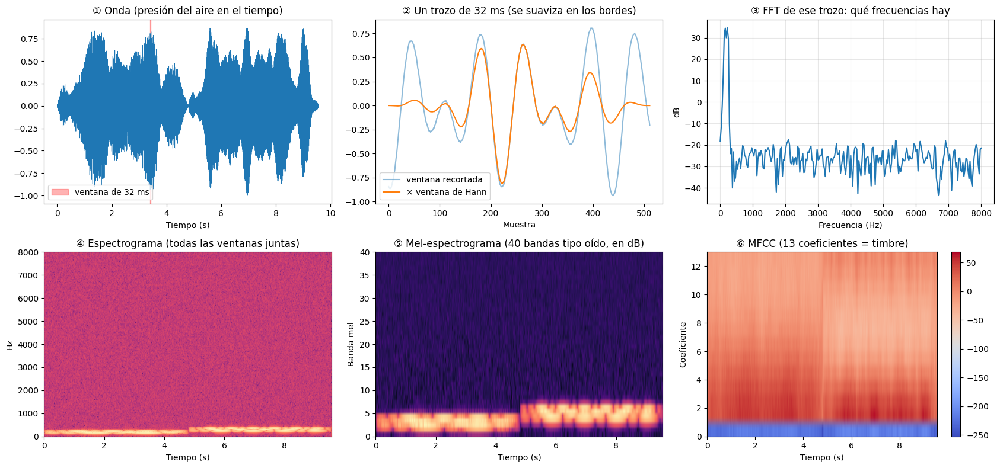

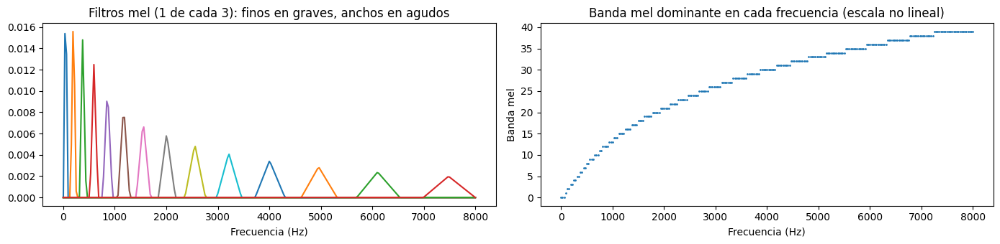

In [4]:
EJEMPLO = 0     # índice del audio a explicar (0 a n-1)
y = senales[EJEMPLO]
S, L, fr = espectrogramas(y)
mf = dct(L, type=2, axis=0, norm="ortho")[:N_MFCC]
tt = np.arange(len(y)) / SR
f_ini = np.argmax(np.sqrt((fr ** 2).mean(1)))          # el trozo más fuerte
t_ini = f_ini * HOP / SR
print("Audio de ejemplo:", nombres[EJEMPLO], "| duración:", round(len(y) / SR, 2), "s")
display(Audio(y, rate=SR))

fig, axs = plt.subplots(2, 3, figsize=(17, 8))
ax = axs[0, 0]; ax.plot(tt, y, lw=.6); ax.axvspan(t_ini, t_ini + N_FFT / SR, color="red", alpha=.3, label="ventana de 32 ms")
ax.set_title("① Onda (presión del aire en el tiempo)"); ax.set_xlabel("Tiempo (s)"); ax.legend()

ax = axs[0, 1]; ax.plot(fr[f_ini], alpha=.5, label="ventana recortada"); ax.plot(fr[f_ini] * VENT, label="× ventana de Hann")
ax.set_title("② Un trozo de 32 ms (se suaviza en los bordes)"); ax.set_xlabel("Muestra"); ax.legend()

ax = axs[0, 2]; ax.plot(FREQS, 20 * np.log10(S[:, f_ini] + 1e-6)); ax.set_title("③ FFT de ese trozo: qué frecuencias hay")
ax.set_xlabel("Frecuencia (Hz)"); ax.set_ylabel("dB"); ax.grid(alpha=.3)

ax = axs[1, 0]; ax.imshow(20 * np.log10(S + 1e-6), origin="lower", aspect="auto", cmap="magma",
                         extent=[0, len(y) / SR, 0, SR / 2])
ax.set_title("④ Espectrograma (todas las ventanas juntas)"); ax.set_xlabel("Tiempo (s)"); ax.set_ylabel("Hz")

ax = axs[1, 1]; ax.imshow(L, origin="lower", aspect="auto", cmap="magma", extent=[0, len(y) / SR, 0, N_MELS])
ax.set_title("⑤ Mel-espectrograma (40 bandas tipo oído, en dB)"); ax.set_xlabel("Tiempo (s)"); ax.set_ylabel("Banda mel")

ax = axs[1, 2]; im = ax.imshow(mf, origin="lower", aspect="auto", cmap="coolwarm", extent=[0, len(y) / SR, 0, N_MFCC])
ax.set_title("⑥ MFCC (13 coeficientes = timbre)"); ax.set_xlabel("Tiempo (s)"); ax.set_ylabel("Coeficiente"); plt.colorbar(im, ax=ax)
plt.tight_layout(); guardar("01_paso_a_paso.png"); plt.show()

# Banco de filtros mel
fig, axs = plt.subplots(1, 2, figsize=(14, 3.5))
for fila in FB[::3]: axs[0].plot(FREQS, fila)
axs[0].set_title("Filtros mel (1 de cada 3): finos en graves, anchos en agudos"); axs[0].set_xlabel("Frecuencia (Hz)")
axs[1].plot(FREQS, np.argmax(FB, axis=0), ".", ms=2); axs[1].set_title("Banda mel dominante en cada frecuencia (escala no lineal)")
axs[1].set_xlabel("Frecuencia (Hz)"); axs[1].set_ylabel("Banda mel")
plt.tight_layout(); plt.show()

### Cada sonido tiene "huella" distinta
Un audio de cada clase (o los primeros 9 audios si no hay etiquetas), como mel-espectrograma. Si a ti te parecen distintos, un algoritmo también podrá separarlos.

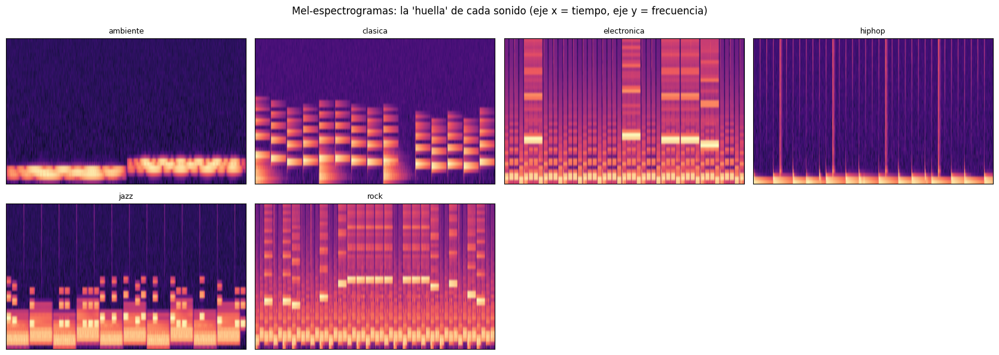

In [5]:
if TIENE_REAL:
    clases_real = sorted(set(y_real))
    ejemplos = [int(np.where(y_real == c)[0][0]) for c in clases_real[:12]]
else:
    ejemplos = list(range(min(9, n)))
nc = min(4, len(ejemplos)); nr = math.ceil(len(ejemplos) / nc)
fig, axs = plt.subplots(nr, nc, figsize=(4.2 * nc, 3 * nr), squeeze=False)
for ax in axs.flatten(): ax.axis("off")
for ax, i in zip(axs.flatten(), ejemplos):
    ax.axis("on"); ax.imshow(MELS[i], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(str(y_real[i]) if TIENE_REAL else nombres[i], fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Mel-espectrogramas: la 'huella' de cada sonido (eje x = tiempo, eje y = frecuencia)")
plt.tight_layout(); guardar("02_galeria_mel.png"); plt.show()

## 3) Estandarizar, ponderar y reducir con PCA
- **Estandarizar** (media 0, desviación 1): si no, el centroide en Hz (miles) aplastaría a una característica de 0.01.
- **Pesos por grupo** (`PESOS`): para que el grupo con más columnas (MFCC) no domine siempre.
- **PCA**: deja `N_PCA` combinaciones de las características. Con ~90 columnas las distancias se parecen entre sí (*maldición de la dimensionalidad*) y DBSCAN/HDBSCAN/OPTICS sufren; con ~10 componentes funcionan mucho mejor.

Datos para clustering: 72 audios × 10 dimensiones (PCA conserva 91.3% de la varianza)


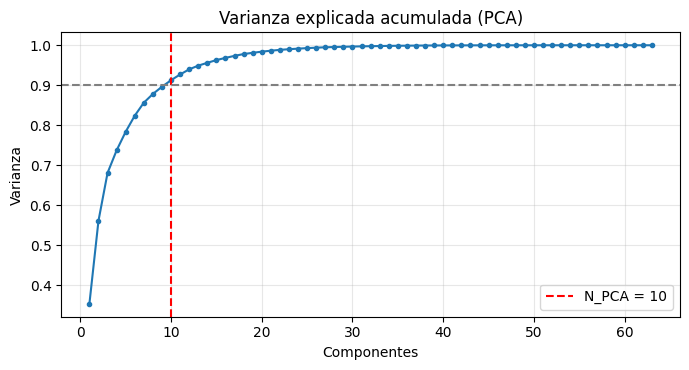

In [6]:
Z = StandardScaler().fit_transform(df.values)
pesos_col = np.array([PESOS[c.split("_")[0]] for c in df.columns])
Xw = Z * pesos_col

pca_c = PCA(n_components=min(N_PCA, Xw.shape[1], n - 1), random_state=SEMILLA).fit(Xw) if N_PCA else None
Xc = pca_c.transform(Xw) if pca_c is not None else Xw
print(f"Datos para clustering: {Xc.shape[0]} audios × {Xc.shape[1]} dimensiones"
      + (f" (PCA conserva {pca_c.explained_variance_ratio_.sum():.1%} de la varianza)" if pca_c is not None else ""))

pca2 = PCA(n_components=2, random_state=SEMILLA).fit(Xw); Z2 = pca2.transform(Xw)
T2 = TSNE(n_components=2, perplexity=max(5, min(30, (n - 1) / 3 - 1)), init="pca",
          learning_rate="auto", random_state=SEMILLA).fit_transform(Xw)

acum = np.cumsum(PCA().fit(Xw).explained_variance_ratio_)
plt.figure(figsize=(7, 3.8)); plt.plot(range(1, len(acum) + 1), acum, "o-", ms=3)
if pca_c is not None: plt.axvline(pca_c.n_components_, color="red", ls="--", label=f"N_PCA = {pca_c.n_components_}"); plt.legend()
plt.axhline(0.9, color="gray", ls="--"); plt.grid(alpha=.3)
plt.title("Varianza explicada acumulada (PCA)"); plt.xlabel("Componentes"); plt.ylabel("Varianza")
plt.tight_layout(); plt.show()

## 4) Utilidades compartidas
Colores, proyecciones 2D (PCA y **t-SNE**), métricas, estabilidad y los gráficos propios del sonido: **matriz de distancias ordenada por cluster**, **audio representante de cada grupo** (con reproductor) y **perfil espectral**.

In [7]:
cmap = plt.colormaps["tab20"]
def color_cluster(k):  return "#000000" if k == -1 else mcolors.rgb2hex(cmap(int(k) % 20)[:3])
def nombre_cluster(k): return "Ruido" if k == -1 else f"Cluster {k}"

def codo_auto(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn = (x - x.min()) / (x.max() - x.min() + 1e-12); yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    d = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0])
    return x[int(np.argmax(d))]

def a_pca2(centros):
    return pca2.transform(pca_c.inverse_transform(centros) if pca_c is not None else centros)

def dibujar_2d(ax, P, etiq, titulo, centros=None):
    for k in sorted(set(etiq)):
        m = etiq == k
        ax.scatter(P[m, 0], P[m, 1], s=35, alpha=.75, color=color_cluster(k), marker="x" if k == -1 else "o",
                   label=f"{nombre_cluster(k)} ({m.sum()})")
    if centros is not None:
        c = a_pca2(centros); ax.scatter(c[:, 0], c[:, 1], marker="X", s=220, c="black", edgecolors="white", label="Centroides")
    ax.set_title(titulo, fontsize=10); ax.grid(alpha=.3)
    if len(set(etiq)) <= 14: ax.legend(fontsize=7)

def graficar_2d(etiq, titulo, archivo, centros=None):
    fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
    dibujar_2d(axs[0], Z2, etiq, titulo + " – PCA", centros); axs[0].set_xlabel("PC1"); axs[0].set_ylabel("PC2")
    dibujar_2d(axs[1], T2, etiq, titulo + " – t-SNE (vecindades)"); axs[1].set_xlabel("t-SNE 1"); axs[1].set_ylabel("t-SNE 2")
    plt.tight_layout(); guardar(archivo); plt.show()

def graficar_silhouette(etiq, titulo, archivo):
    m = etiq != -1; cl = sorted(set(etiq[m]))
    if len(cl) < 2: print(f"{titulo}: menos de 2 clusters, no hay silhouette."); return
    s = silhouette_samples(Xc[m], etiq[m]); e = etiq[m]
    plt.figure(figsize=(8, 5.5)); y0 = 0
    for k in cl:
        v = np.sort(s[e == k]); plt.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=color_cluster(k), label=nombre_cluster(k)); y0 += len(v) + 3
    plt.axvline(s.mean(), color="red", ls="--", label=f"Promedio = {s.mean():.2f}")
    plt.title(titulo + " (sin ruido)"); plt.xlabel("Coeficiente de silhouette"); plt.yticks([])
    if len(cl) <= 14: plt.legend(fontsize=8)
    plt.tight_layout(); guardar(archivo); plt.show()

def graficar_matriz_dist(etiq, titulo, archivo, max_n=1200):
    # Distancia entre todos los pares de audios, ordenados por cluster: un buen clustering = bloques oscuros en la diagonal
    rng = np.random.default_rng(SEMILLA)
    idx = np.arange(n) if n <= max_n else np.sort(rng.choice(n, max_n, replace=False))
    orden = idx[np.argsort(etiq[idx], kind="stable")]
    D = cdist(Xc[orden], Xc[orden]); e = etiq[orden]
    fig, ax = plt.subplots(figsize=(6.5, 6))
    im = ax.imshow(D, cmap="viridis_r"); plt.colorbar(im, fraction=.046, label="distancia (oscuro = parecidos)")
    for b in np.where(np.diff(e) != 0)[0]: ax.axhline(b + .5, color="white", lw=.6); ax.axvline(b + .5, color="white", lw=.6)
    ax.set_title(titulo + "\nmatriz de distancias ordenada por cluster"); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); guardar(archivo); plt.show()

def dominante(etiq, k):
    if not TIENE_REAL: return ""
    c = Counter(y_real[etiq == k]).most_common(1)[0]; return f" · {c[0]} {c[1] / (etiq == k).sum():.0%}"

def medoide(etiq, k):
    idx = np.where(etiq == k)[0]; c = Xc[idx].mean(0)
    return idx[np.argmin(((Xc[idx] - c) ** 2).sum(1))]

def mostrar_representantes(etiq, nombre, archivo, max_cl=8):
    # El audio más "central" de cada cluster: mel-espectrograma + reproductor
    cl = sorted([k for k in set(etiq) if k != -1], key=lambda k: -(etiq == k).sum())[:max_cl]
    if not cl: print(f"{nombre}: no hay clusters que mostrar."); return
    nc = min(4, len(cl)); nr = math.ceil(len(cl) / nc)
    fig, axs = plt.subplots(nr, nc, figsize=(4.2 * nc, 3 * nr), squeeze=False)
    for ax in axs.flatten(): ax.axis("off")
    meds = {}
    for ax, k in zip(axs.flatten(), cl):
        i = medoide(etiq, k); meds[k] = i; ax.axis("on")
        ax.imshow(MELS[i], origin="lower", aspect="auto", cmap="magma"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"C{k} (n={(etiq == k).sum()}){dominante(etiq, k)}", fontsize=9, color=color_cluster(k))
    plt.suptitle(f"{nombre}: audio representante de cada cluster"); plt.tight_layout(); guardar(archivo); plt.show()
    if ESCUCHAR:
        for k in cl[:N_ESCUCHAR]:
            print(f"▶ {nombre} – Cluster {k} (n={(etiq == k).sum()}){dominante(etiq, k)} – {nombres[meds[k]]}")
            display(Audio(senales[meds[k]], rate=SR))

def mostrar_atipicos(etiq, nombre, max_n=6, escuchar=ESCUCHAR):
    idx = np.where(etiq == -1)[0]
    if len(idx) == 0: print(f"{nombre}: no marcó ruido."); return
    print(f"{nombre}: {len(idx)} audios atípicos. Se muestran {min(max_n, len(idx))}:")
    idx = idx[:max_n]; nc = min(3, len(idx)); nr = math.ceil(len(idx) / nc)
    fig, axs = plt.subplots(nr, nc, figsize=(4.5 * nc, 3 * nr), squeeze=False)
    for ax in axs.flatten(): ax.axis("off")
    for ax, i in zip(axs.flatten(), idx):
        ax.axis("on"); ax.imshow(MELS[i], origin="lower", aspect="auto", cmap="magma"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{nombres[i]}" + (f" [{y_real[i]}]" if TIENE_REAL else ""), fontsize=8)
    plt.tight_layout(); plt.show()
    if escuchar:
        for i in idx[:3]: print("▶", nombres[i]); display(Audio(senales[i], rate=SR))

def graficar_perfil(etiq, titulo, archivo):
    # Qué características distinguen a cada cluster (z-score medio)
    cols = [c for c in df.columns if c.startswith(("esp_", "tiempo_", "bandas_", "ritmo_", "tono_")) and not c.endswith("_std")]
    z = pd.DataFrame(Z, columns=df.columns)[cols]
    cl = [k for k in sorted(set(etiq)) if k != -1][:20]
    if not cl: return
    perfil = np.array([z[etiq == k].mean().values for k in cl])
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(cl) + 3))
    im = ax.imshow(perfil, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=75, ha="right", fontsize=8)
    ax.set_yticks(range(len(cl))); ax.set_yticklabels([f"C{k}" for k in cl])
    plt.colorbar(im, label="z-score (rojo = por encima del promedio)"); ax.set_title(titulo + ": perfil de cada cluster")
    plt.tight_layout(); guardar(archivo); plt.show()

def metricas_internas(X_, lab):
    m = lab != -1
    if len(set(lab[m])) < 2 or m.sum() <= len(set(lab[m])): return dict(silhouette=np.nan, calinski=np.nan, davies_bouldin=np.nan)
    return dict(silhouette=silhouette_score(X_[m], lab[m]), calinski=calinski_harabasz_score(X_[m], lab[m]),
                davies_bouldin=davies_bouldin_score(X_[m], lab[m]))

def barrido(valores, ajustar):
    filas = []
    for v in valores:
        lab = ajustar(v); m = lab != -1
        filas.append(dict(valor=v, n_clusters=len(set(lab[m])), ruido=1 - m.mean(), **metricas_internas(Xc, lab)))
    return pd.DataFrame(filas)

def elegir(df_b, manual, defecto, texto_defecto):
    if manual is not None: return manual, "manual"
    validos = df_b[(df_b.n_clusters >= 2) & (df_b.ruido <= MAX_RUIDO)].dropna(subset=["silhouette"])
    if len(validos): return validos.loc[validos.silhouette.idxmax(), "valor"], f"mejor silhouette con ruido <= {MAX_RUIDO:.0%}"
    return defecto, texto_defecto

def graficar_barrido(df_b, param, elegido, titulo, archivo, extra, etiq_final):
    fig, axs = plt.subplots(2, 3, figsize=(17, 9)); extra(axs[0, 0])
    ax = axs[0, 1]; ax.plot(df_b.valor, df_b.n_clusters, "o-", color="tab:blue"); ax.set_ylabel("Nº de clusters", color="tab:blue")
    ax2 = ax.twinx(); ax2.plot(df_b.valor, df_b.ruido * 100, "s--", color="tab:orange"); ax2.set_ylabel("% de ruido", color="tab:orange")
    ax.axvline(elegido, color="red", ls="--", alpha=.6); ax.set_title(f"Clusters y ruido según {param}", fontsize=10); ax.set_xlabel(param)
    if TIENE_REAL: ax.axhline(len(set(y_real)), color="green", ls=":", label="nº de clases reales"); ax.legend(fontsize=8)
    for ax, col, tit, nota in [(axs[0, 2], "silhouette", "Silhouette", "mayor es mejor"),
                               (axs[1, 0], "calinski", "Calinski-Harabasz", "mayor es mejor"),
                               (axs[1, 1], "davies_bouldin", "Davies-Bouldin", "menor es mejor")]:
        ax.plot(df_b.valor, df_b[col], "o-"); ax.axvline(elegido, color="red", ls="--", alpha=.6, label=f"{param} usado")
        ax.set_title(f"{tit} vs {param}\n({nota}; sin contar ruido)", fontsize=10); ax.set_xlabel(param); ax.grid(alpha=.3); ax.legend(fontsize=8)
    dibujar_2d(axs[1, 2], T2, etiq_final, f"Resultado final ({param} = {elegido:.3g}) – t-SNE")
    plt.suptitle(titulo, y=1.0); plt.tight_layout(); guardar(archivo); plt.show()
print("Utilidades listas.")

Utilidades listas.


## 5) ¿Los sonidos ya forman grupos? (antes de agrupar)
Si hay etiquetas reales, se colorean los puntos con ellas. Si las clases se ven separadas en el espacio de características, el clustering tiene posibilidades. También se ve **qué características separan mejor** las clases (prueba ANOVA F).

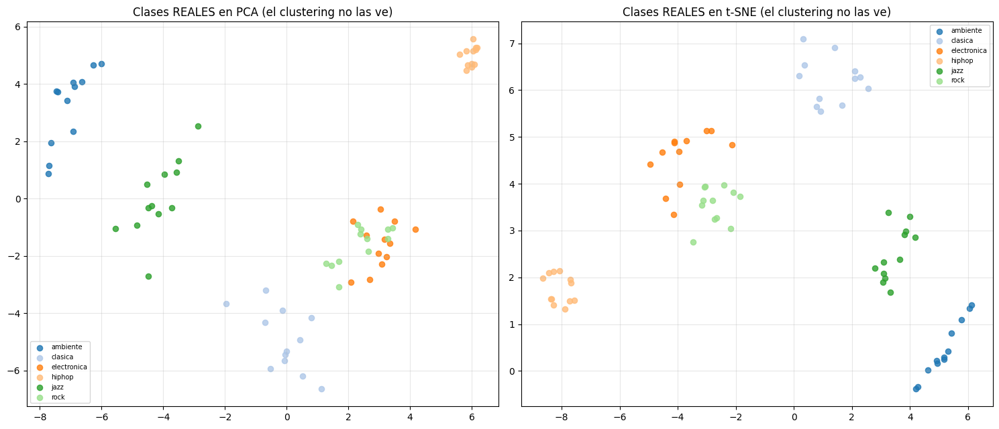

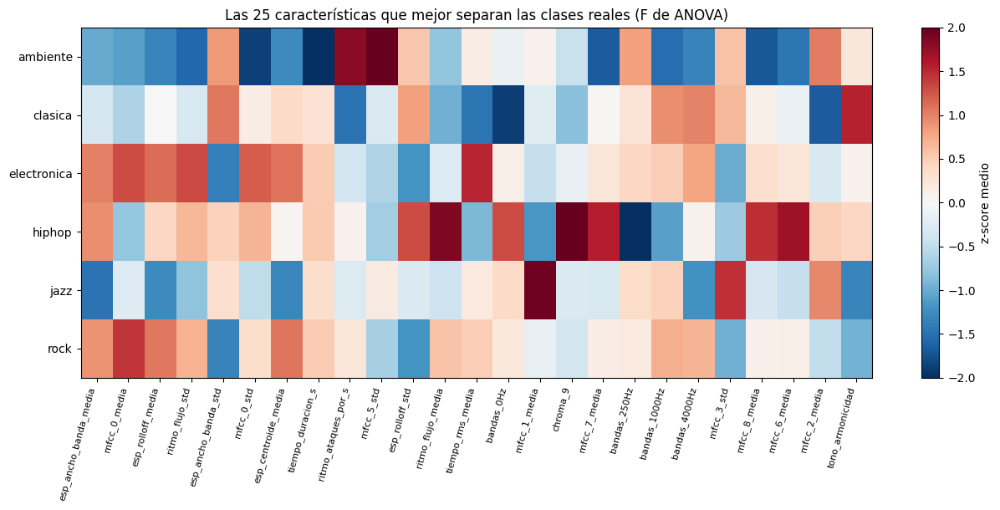

In [8]:
if TIENE_REAL:
    clases_real = sorted(set(y_real)); cr = {c: i for i, c in enumerate(clases_real)}
    fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
    for ax, P, nom in [(axs[0], Z2, "PCA"), (axs[1], T2, "t-SNE")]:
        for c in clases_real:
            m = y_real == c; ax.scatter(P[m, 0], P[m, 1], s=35, alpha=.8, color=cmap(cr[c] % 20), label=str(c))
        ax.set_title(f"Clases REALES en {nom} (el clustering no las ve)"); ax.grid(alpha=.3)
        if len(clases_real) <= 14: ax.legend(fontsize=7)
    plt.tight_layout(); guardar("03_clases_reales.png"); plt.show()

    # Características más discriminantes
    F, _ = f_classif(Z, y_real); orden = np.argsort(-np.nan_to_num(F))[:25]
    perfil = pd.DataFrame(Z[:, orden], columns=df.columns[orden]).groupby(y_real).mean()
    fig, ax = plt.subplots(figsize=(13, 0.45 * len(clases_real) + 3.5))
    im = ax.imshow(perfil.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(len(orden))); ax.set_xticklabels(perfil.columns, rotation=75, ha="right", fontsize=8)
    ax.set_yticks(range(len(clases_real))); ax.set_yticklabels(perfil.index)
    plt.colorbar(im, label="z-score medio"); ax.set_title("Las 25 características que mejor separan las clases reales (F de ANOVA)")
    plt.tight_layout(); guardar("04_caracteristicas_clave.png"); plt.show()
else:
    fig, axs = plt.subplots(1, 2, figsize=(14, 6))
    axs[0].scatter(Z2[:, 0], Z2[:, 1], s=30, alpha=.7); axs[0].set_title("Audios en PCA"); axs[1].scatter(T2[:, 0], T2[:, 1], s=30, alpha=.7); axs[1].set_title("Audios en t-SNE")
    for a in axs: a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 6) ¿Cuántos clusters? Codo, Silhouette, Calinski-Harabasz y Davies-Bouldin

Silhouette sugiere k = 8 (jerárquico) y k = 6 (K-Means) | codo K-Means: k = 5 | k usado: 8 | clases reales: 6


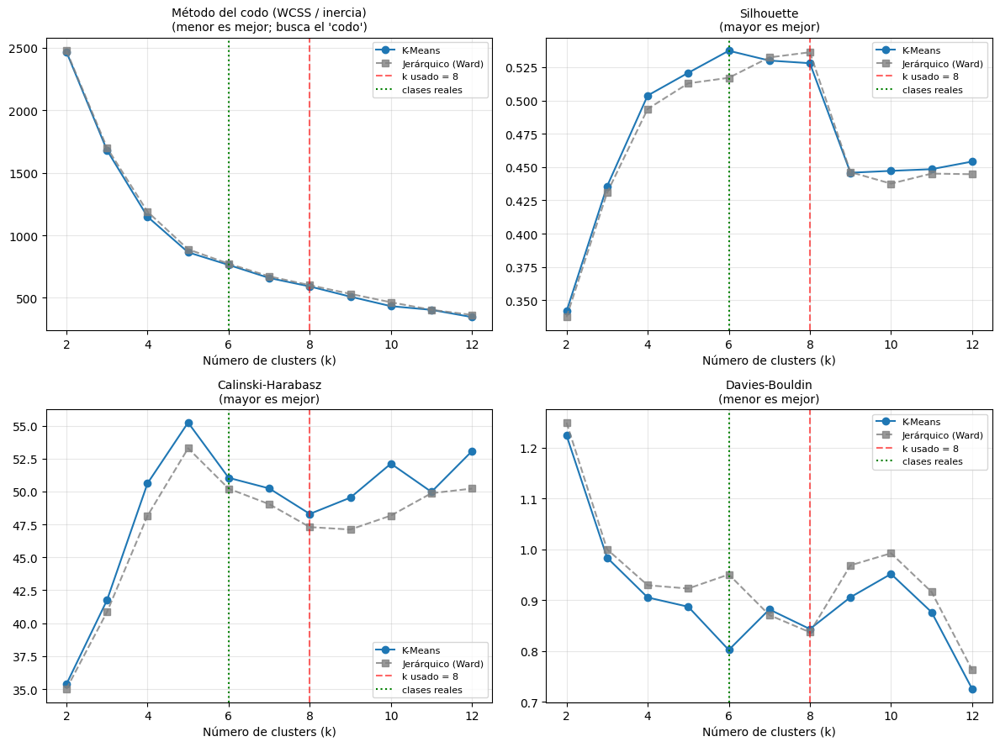

In [9]:
k_max = min(K_MAX, n - 1); ks = list(range(2, k_max + 1))
linked = linkage(Xc, method="ward")
wcss_w, sil_w, ch_w, db_w, wcss_k, sil_k, ch_k, db_k = [], [], [], [], [], [], [], []
for k in ks:
    lw = fcluster(linked, k, criterion="maxclust") - 1
    wcss_w.append(sum(((Xc[lw == c] - Xc[lw == c].mean(0)) ** 2).sum() for c in np.unique(lw)))
    sil_w.append(silhouette_score(Xc, lw)); ch_w.append(calinski_harabasz_score(Xc, lw)); db_w.append(davies_bouldin_score(Xc, lw))
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xc); wcss_k.append(km.inertia_)
    sil_k.append(silhouette_score(Xc, km.labels_)); ch_k.append(calinski_harabasz_score(Xc, km.labels_)); db_k.append(davies_bouldin_score(Xc, km.labels_))

k_auto = ks[int(np.argmax(sil_w))]; K = K_ELEGIDO if K_ELEGIDO else k_auto
print(f"Silhouette sugiere k = {k_auto} (jerárquico) y k = {ks[int(np.argmax(sil_k))]} (K-Means) | codo K-Means: k = {int(codo_auto(ks, wcss_k))} | k usado: {K}"
      + (f" | clases reales: {len(set(y_real))}" if TIENE_REAL else ""))

fig, axs = plt.subplots(2, 2, figsize=(12, 9))
for ax, (titulo, vk, vw, nota) in zip(axs.flatten(), [("Método del codo (WCSS / inercia)", wcss_k, wcss_w, "menor es mejor; busca el 'codo'"),
        ("Silhouette", sil_k, sil_w, "mayor es mejor"), ("Calinski-Harabasz", ch_k, ch_w, "mayor es mejor"), ("Davies-Bouldin", db_k, db_w, "menor es mejor")]):
    ax.plot(ks, vk, "o-", label="K-Means"); ax.plot(ks, vw, "s--", color="gray", alpha=.8, label="Jerárquico (Ward)")
    ax.axvline(K, color="red", ls="--", alpha=.6, label=f"k usado = {K}")
    if TIENE_REAL: ax.axvline(len(set(y_real)), color="green", ls=":", label="clases reales")
    ax.set_title(f"{titulo}\n({nota})", fontsize=10); ax.set_xlabel("Número de clusters (k)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); guardar("05_metricas_k.png"); plt.show()

## 7) Clustering jerárquico (Ward) y dendrograma
El dendrograma muestra **qué sonidos se fusionan primero** (los más parecidos). Cuanto más alta la unión, más distintos eran los grupos.

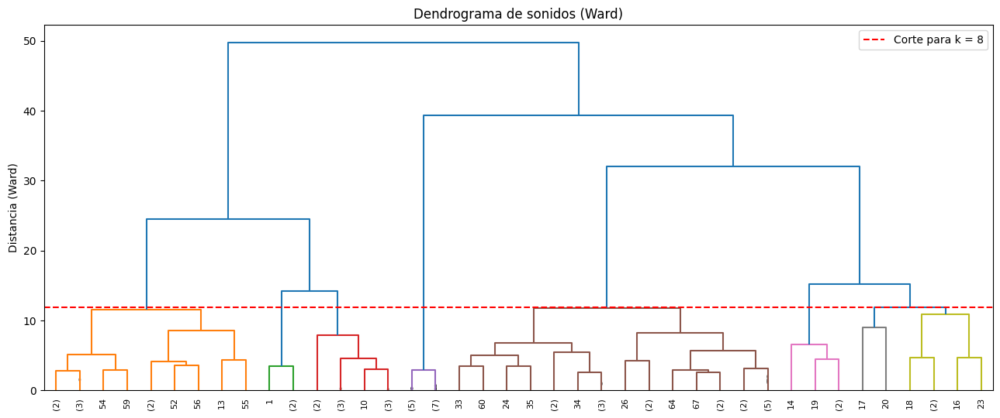

0    24
1    13
2     4
3     2
4     5
5    12
6     3
7     9
Name: audios por cluster (Jerárquico), dtype: int64


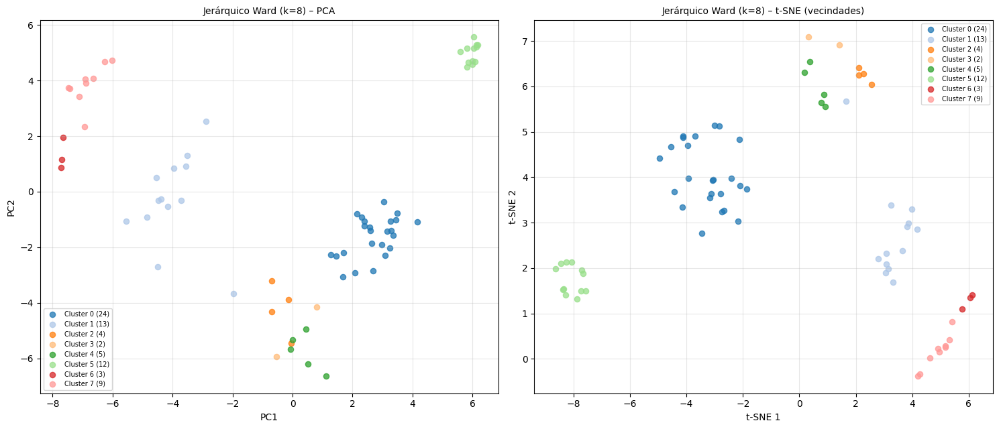

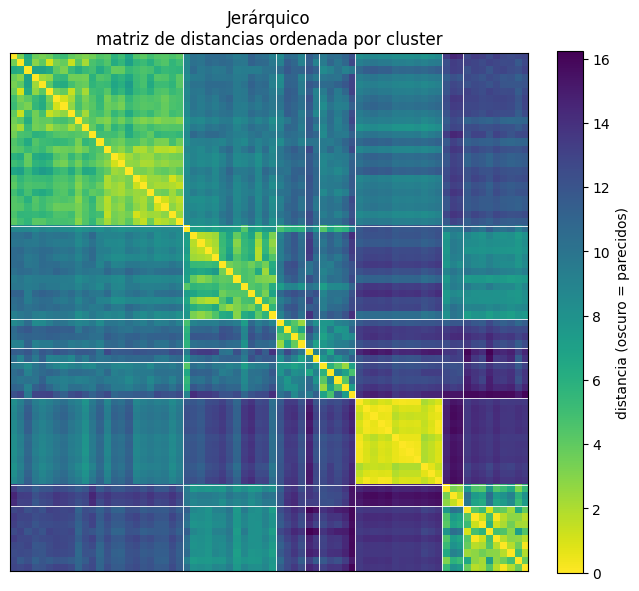

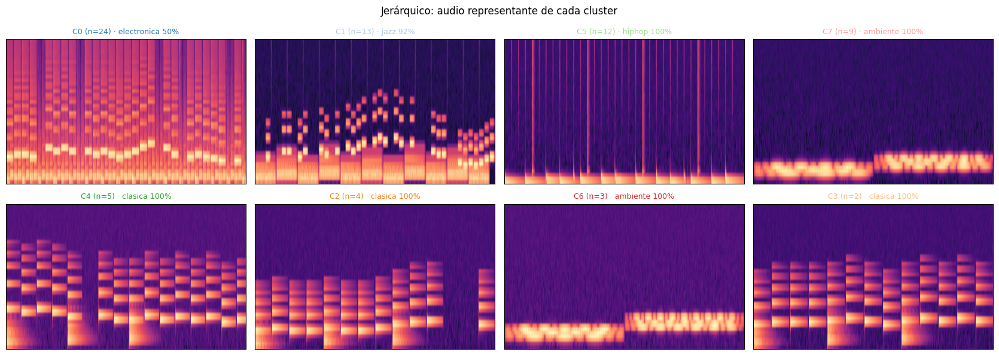

▶ Jerárquico – Cluster 0 (n=24) · electronica 50% – rock/rock_001.wav


▶ Jerárquico – Cluster 1 (n=13) · jazz 92% – jazz/jazz_006.wav


▶ Jerárquico – Cluster 5 (n=12) · hiphop 100% – hiphop/hiphop_003.wav


▶ Jerárquico – Cluster 7 (n=9) · ambiente 100% – ambiente/ambiente_008.wav


In [10]:
etiquetas_jer = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xc)
corte = (linked[-K, 2] + linked[-(K - 1), 2]) / 2 if K > 1 else None
plt.figure(figsize=(13, 5.5))
dendrogram(linked, truncate_mode="lastp", p=40, leaf_rotation=90, leaf_font_size=8, show_contracted=True, color_threshold=corte)
plt.axhline(corte, color="red", ls="--", label=f"Corte para k = {K}"); plt.legend()
plt.title("Dendrograma de sonidos (Ward)"); plt.ylabel("Distancia (Ward)"); plt.tight_layout(); guardar("06_dendrograma.png"); plt.show()

print(pd.Series(etiquetas_jer).value_counts().sort_index().rename("audios por cluster (Jerárquico)"))
graficar_2d(etiquetas_jer, f"Jerárquico Ward (k={K})", "07_jerarquico_2d.png")
graficar_matriz_dist(etiquetas_jer, "Jerárquico", "08_jerarquico_dist.png")
mostrar_representantes(etiquetas_jer, "Jerárquico", "09_jerarquico_repr.png")

## 8) K-Means
Los **centroides** son el "sonido promedio" de cada grupo. El perfil muestra en qué características se distingue cada cluster.

0    12
1     5
2    24
3     9
4     9
5     7
6     3
7     3
Name: audios por cluster (K-Means), dtype: int64
Inercia final: 591.09


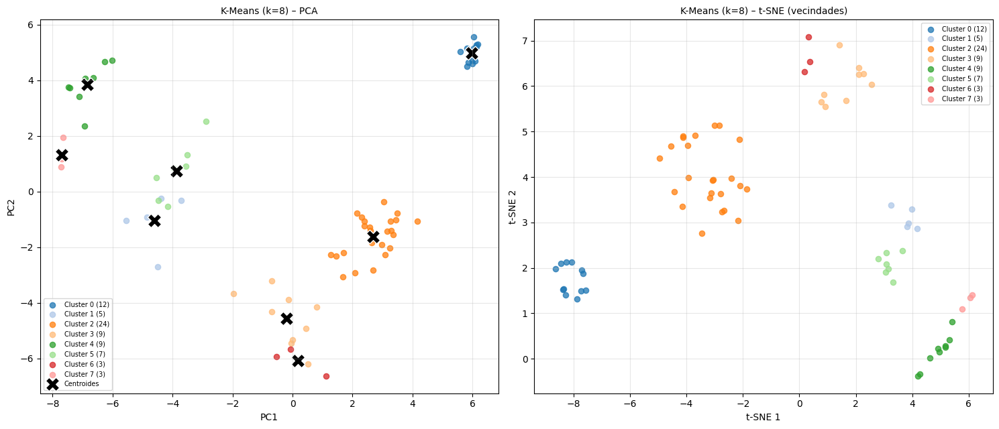

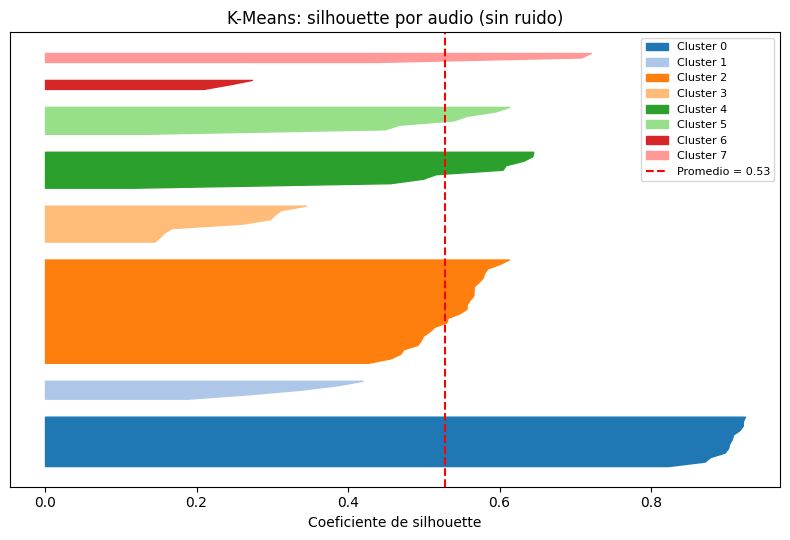

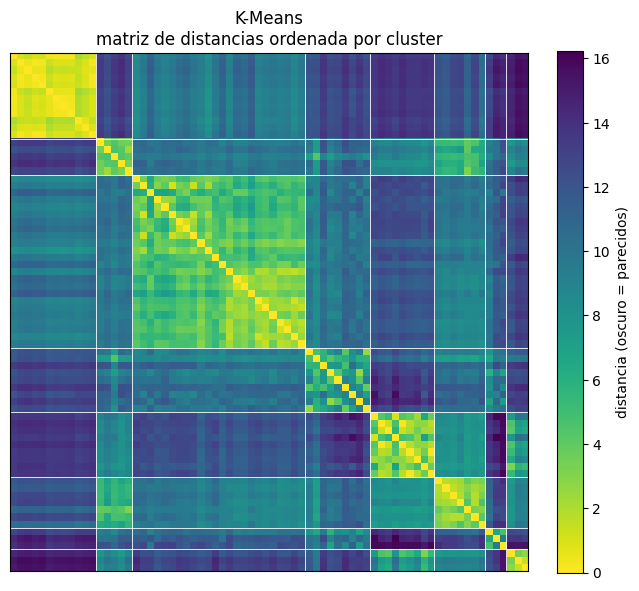

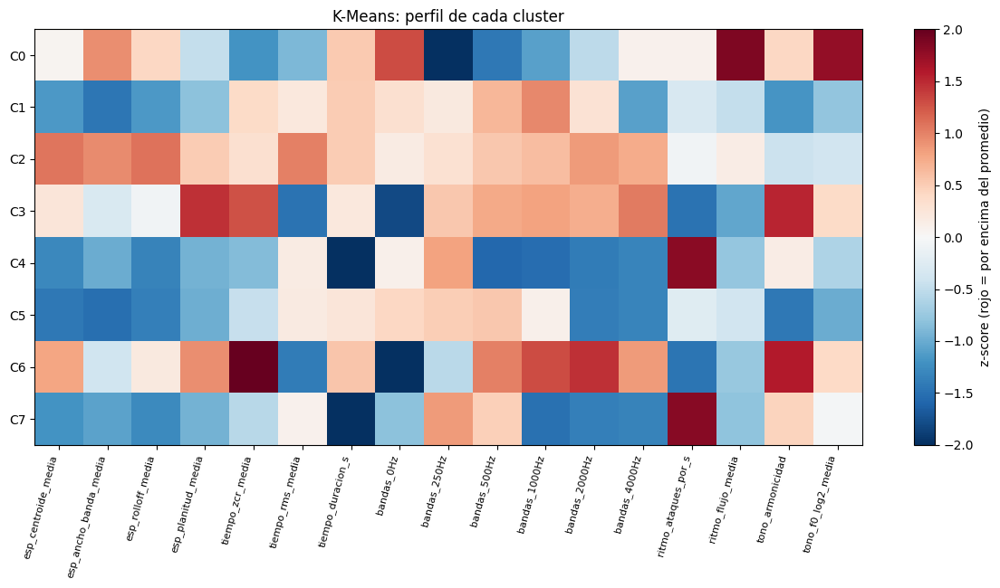

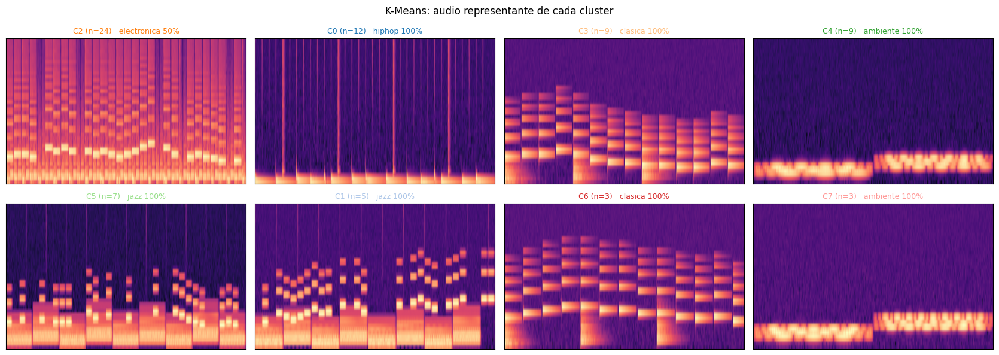

▶ K-Means – Cluster 2 (n=24) · electronica 50% – rock/rock_001.wav


▶ K-Means – Cluster 0 (n=12) · hiphop 100% – hiphop/hiphop_003.wav


▶ K-Means – Cluster 3 (n=9) · clasica 100% – clasica/clasica_001.wav


▶ K-Means – Cluster 4 (n=9) · ambiente 100% – ambiente/ambiente_008.wav


In [11]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Xc)
etiquetas_km = kmeans.labels_
print(pd.Series(etiquetas_km).value_counts().sort_index().rename("audios por cluster (K-Means)")); print(f"Inercia final: {kmeans.inertia_:.2f}")
graficar_2d(etiquetas_km, f"K-Means (k={K})", "10_kmeans_2d.png", centros=kmeans.cluster_centers_)
graficar_silhouette(etiquetas_km, "K-Means: silhouette por audio", "11_kmeans_silhouette.png")
graficar_matriz_dist(etiquetas_km, "K-Means", "12_kmeans_dist.png")
graficar_perfil(etiquetas_km, "K-Means", "13_kmeans_perfil.png")
mostrar_representantes(etiquetas_km, "K-Means", "14_kmeans_repr.png")

## 9) DBSCAN
`eps` = qué tan cerca deben estar dos sonidos para ser "vecinos"; `min_samples` = vecinos necesarios para formar un núcleo. Lo que queda aislado es **ruido**: en sonido suele ser un **audio raro** (grabación mala, evento distinto) — por eso estos modelos sirven para **detectar anomalías**.

eps del codo: 4.444 | eps usado: 2.857 (mejor silhouette con ruido <= 40%) | min_samples = 5
DBSCAN: 5 clusters y 28 audios de ruido (38.9%).


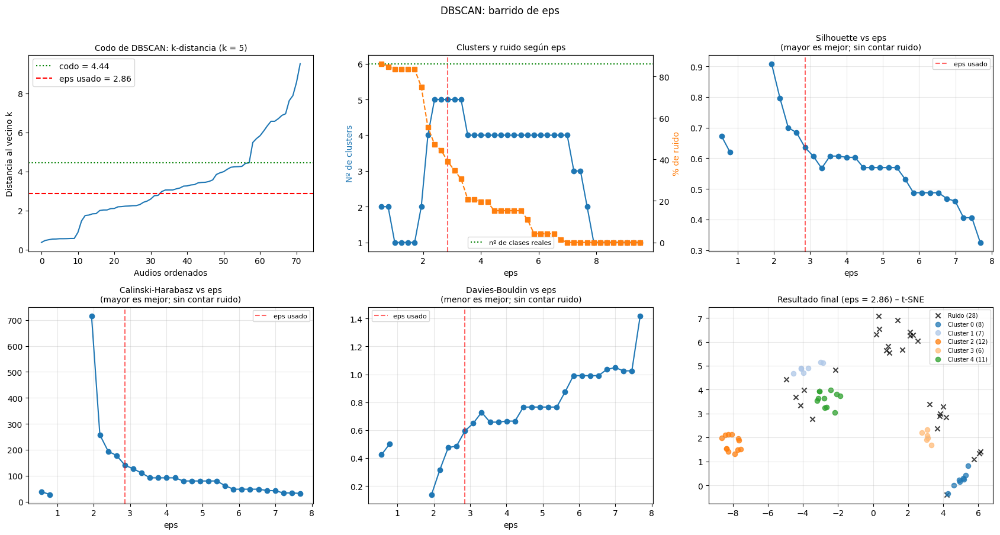

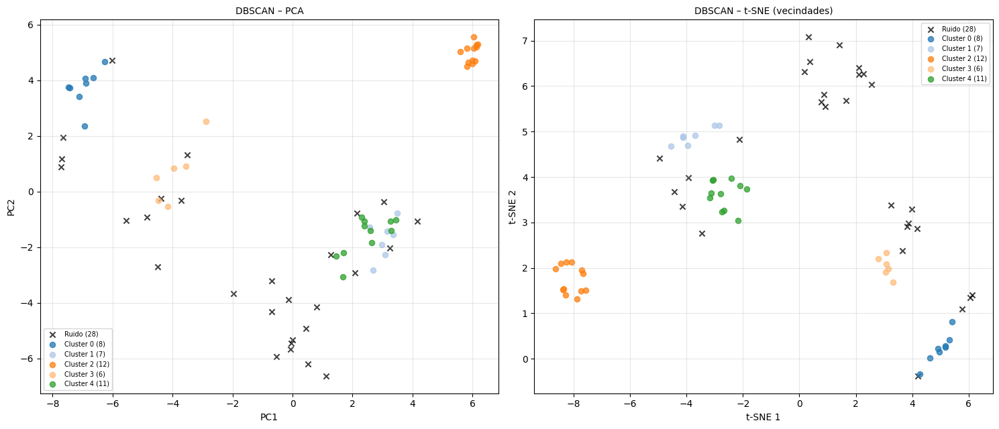

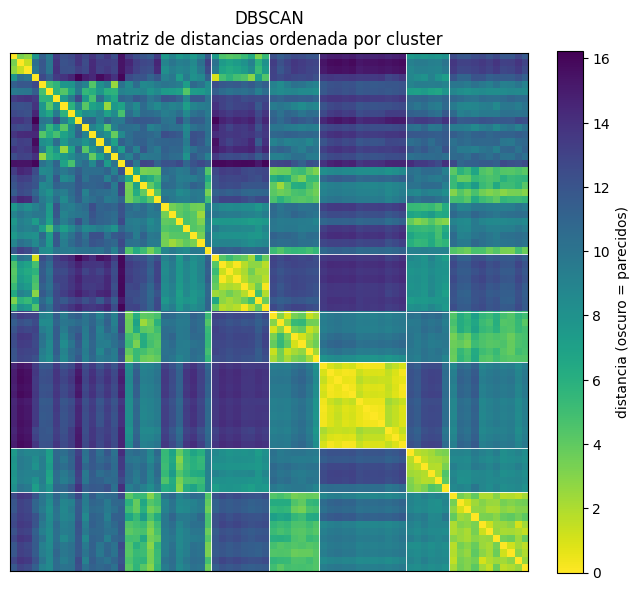

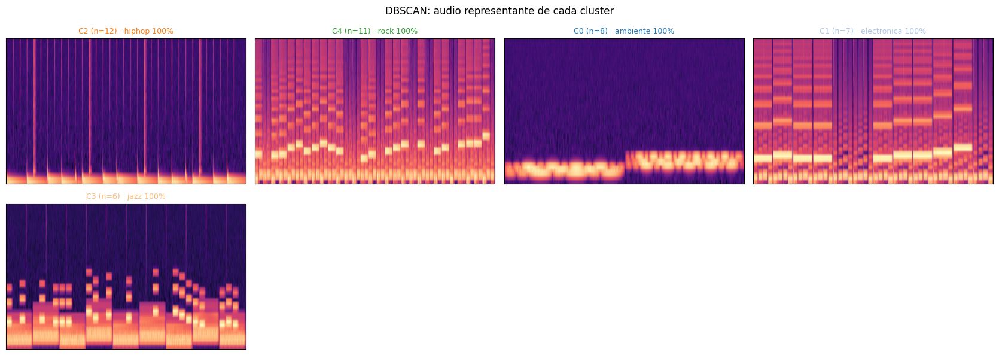

▶ DBSCAN – Cluster 2 (n=12) · hiphop 100% – hiphop/hiphop_003.wav


▶ DBSCAN – Cluster 4 (n=11) · rock 100% – rock/rock_006.wav


▶ DBSCAN – Cluster 0 (n=8) · ambiente 100% – ambiente/ambiente_007.wav


▶ DBSCAN – Cluster 1 (n=7) · electronica 100% – electronica/electronica_008.wav


DBSCAN: 28 audios atípicos. Se muestran 6:


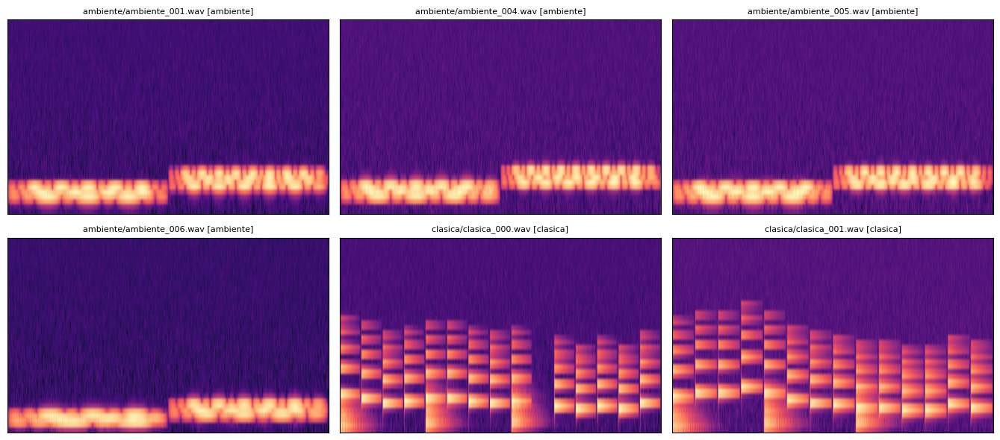

▶ ambiente/ambiente_001.wav


▶ ambiente/ambiente_004.wav


▶ ambiente/ambiente_005.wav


In [12]:
vec = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xc)
k_dist = np.sort(vec.kneighbors(Xc)[0][:, -1])
eps_codo = float(max(k_dist[int(codo_auto(np.arange(len(k_dist)), k_dist))], 0.05))
eps_grid = np.linspace(max(np.percentile(k_dist, 10), 0.05), max(k_dist.max(), 0.2), 40)
df_eps = barrido(eps_grid, lambda e: DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(Xc))
eps_db, origen = elegir(df_eps, EPS_ELEGIDO, eps_codo, "codo de k-distancia (ningún eps dio >= 2 clusters con poco ruido)"); eps_db = float(eps_db)
print(f"eps del codo: {eps_codo:.3f} | eps usado: {eps_db:.3f} ({origen}) | min_samples = {MIN_SAMPLES}")

etiquetas_db = DBSCAN(eps=eps_db, min_samples=MIN_SAMPLES).fit_predict(Xc)
print(f"DBSCAN: {len(set(etiquetas_db[etiquetas_db != -1]))} clusters y {(etiquetas_db == -1).sum()} audios de ruido ({(etiquetas_db == -1).mean():.1%}).")

def extra_dbscan(ax):
    ax.plot(k_dist); ax.axhline(eps_codo, color="green", ls=":", label=f"codo = {eps_codo:.2f}"); ax.axhline(eps_db, color="red", ls="--", label=f"eps usado = {eps_db:.2f}")
    ax.set_title(f"Codo de DBSCAN: k-distancia (k = {MIN_SAMPLES})", fontsize=10); ax.set_xlabel("Audios ordenados"); ax.set_ylabel("Distancia al vecino k"); ax.legend()

graficar_barrido(df_eps, "eps", eps_db, "DBSCAN: barrido de eps", "15_dbscan_barrido.png", extra_dbscan, etiquetas_db)
graficar_2d(etiquetas_db, "DBSCAN", "16_dbscan_2d.png")
graficar_matriz_dist(etiquetas_db, "DBSCAN", "17_dbscan_dist.png")
mostrar_representantes(etiquetas_db, "DBSCAN", "18_dbscan_repr.png")
mostrar_atipicos(etiquetas_db, "DBSCAN")

## 10) HDBSCAN
Prueba **todos los `eps` a la vez** y conserva los clusters más estables; puede encontrar grupos **densos y dispersos en el mismo conjunto** (p. ej., voces muy parecidas entre sí junto a sonidos ambientales variados). `probabilities_` dice qué tan seguro está de cada audio.

min_cluster_size usado: 8 (mejor silhouette con ruido <= 40%)
HDBSCAN: 4 clusters y 13 audios de ruido (18.1%).


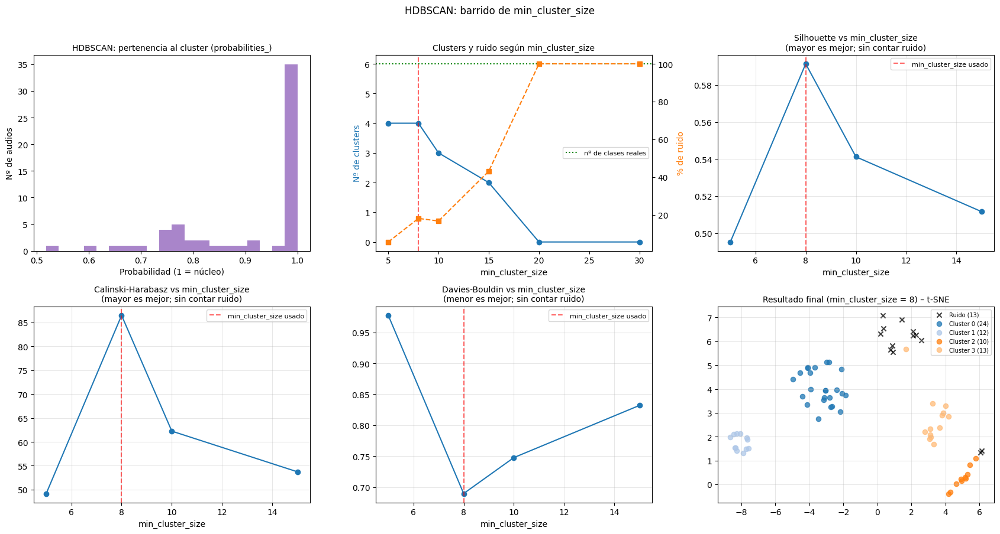

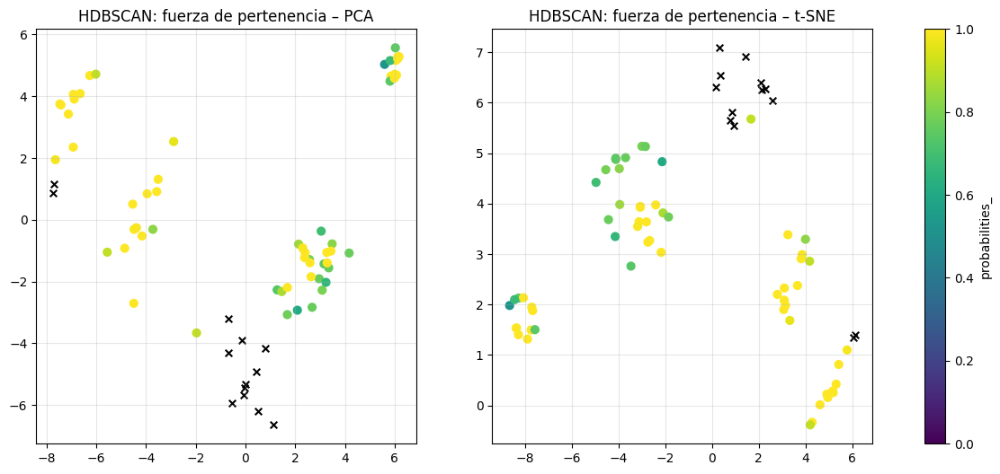

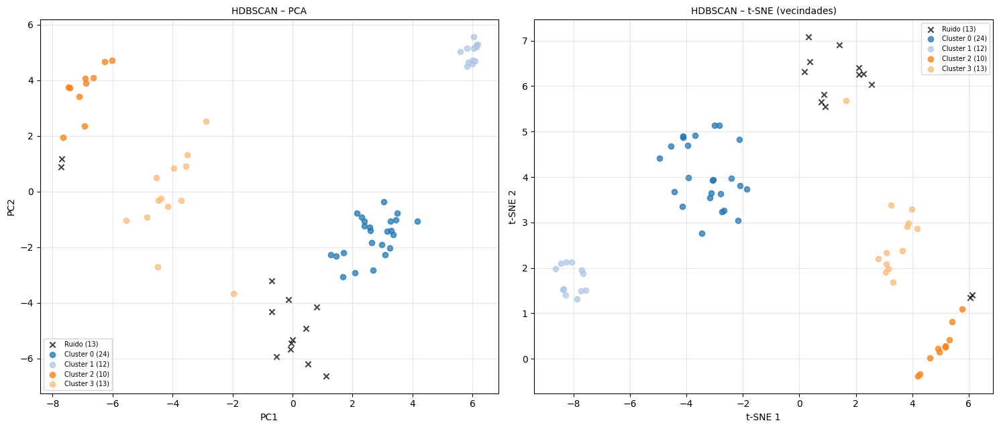

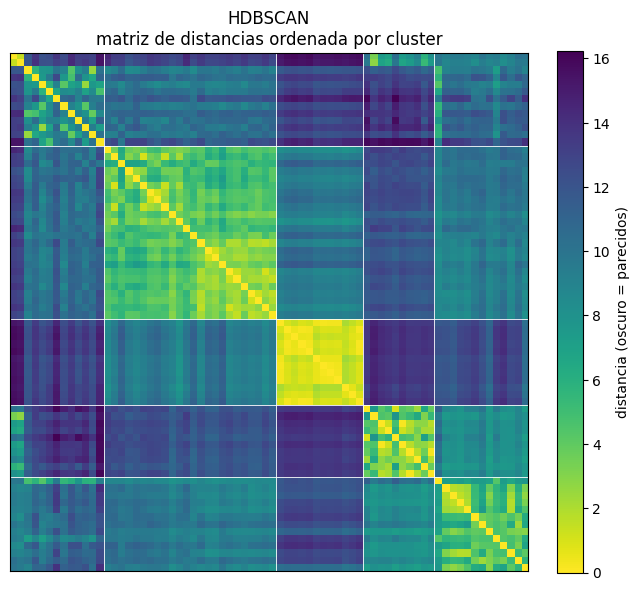

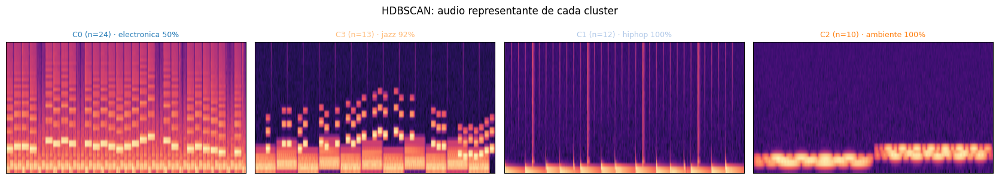

▶ HDBSCAN – Cluster 0 (n=24) · electronica 50% – rock/rock_001.wav


▶ HDBSCAN – Cluster 3 (n=13) · jazz 92% – jazz/jazz_006.wav


▶ HDBSCAN – Cluster 1 (n=12) · hiphop 100% – hiphop/hiphop_003.wav


▶ HDBSCAN – Cluster 2 (n=10) · ambiente 100% – ambiente/ambiente_007.wav


Los 3 audios con menor probabilidad de pertenencia:
▶ ambiente/ambiente_005.wav  (prob=0.00, cluster=-1) [real: ambiente]


▶ ambiente/ambiente_004.wav  (prob=0.00, cluster=-1) [real: ambiente]


▶ clasica/clasica_003.wav  (prob=0.00, cluster=-1) [real: clasica]


In [13]:
grid_mcs = sorted({v for v in (5, 8, 10, 15, 20, 30, 50, 75, 100, 150) if v < n // 2} | {5})
df_mcs = barrido(grid_mcs, lambda m_: HDBSCAN(min_cluster_size=int(m_), min_samples=HDB_MIN_SAMPLES).fit_predict(Xc))
mcs_h, origen = elegir(df_mcs, MCS_ELEGIDO, 10, "valor por defecto"); mcs_h = int(mcs_h)
print(f"min_cluster_size usado: {mcs_h} ({origen})")

hdb = HDBSCAN(min_cluster_size=mcs_h, min_samples=HDB_MIN_SAMPLES).fit(Xc)
etiquetas_hdb = hdb.labels_
print(f"HDBSCAN: {len(set(etiquetas_hdb[etiquetas_hdb != -1]))} clusters y {(etiquetas_hdb == -1).sum()} audios de ruido ({(etiquetas_hdb == -1).mean():.1%}).")

def extra_hdbscan(ax):
    ax.hist(hdb.probabilities_[etiquetas_hdb != -1], bins=20, color="tab:purple", alpha=.8)
    ax.set_title("HDBSCAN: pertenencia al cluster (probabilities_)", fontsize=10); ax.set_xlabel("Probabilidad (1 = núcleo)"); ax.set_ylabel("Nº de audios")

graficar_barrido(df_mcs, "min_cluster_size", mcs_h, "HDBSCAN: barrido de min_cluster_size", "19_hdbscan_barrido.png", extra_hdbscan, etiquetas_hdb)

fig, axs = plt.subplots(1, 2, figsize=(15, 6)); m = etiquetas_hdb != -1
for ax, P, nom in [(axs[0], Z2, "PCA"), (axs[1], T2, "t-SNE")]:
    ax.scatter(P[~m, 0], P[~m, 1], s=30, color="black", marker="x", label="Ruido")
    sc = ax.scatter(P[m, 0], P[m, 1], c=hdb.probabilities_[m], cmap="viridis", s=40, vmin=0, vmax=1); ax.set_title(f"HDBSCAN: fuerza de pertenencia – {nom}"); ax.grid(alpha=.3)
plt.colorbar(sc, ax=axs, label="probabilities_"); guardar("20_hdbscan_prob.png"); plt.show()

graficar_2d(etiquetas_hdb, "HDBSCAN", "21_hdbscan_2d.png")
graficar_matriz_dist(etiquetas_hdb, "HDBSCAN", "22_hdbscan_dist.png")
mostrar_representantes(etiquetas_hdb, "HDBSCAN", "23_hdbscan_repr.png")

# Audios con menor pertenencia (los más "dudosos")
dudosos = np.argsort(hdb.probabilities_)[:3]
print("Los 3 audios con menor probabilidad de pertenencia:")
for i in dudosos:
    print(f"▶ {nombres[i]}  (prob={hdb.probabilities_[i]:.2f}, cluster={etiquetas_hdb[i]})" + (f" [real: {y_real[i]}]" if TIENE_REAL else ""))
    if ESCUCHAR: display(Audio(senales[i], rate=SR))

## 11) OPTICS
Ordena los audios por **distancia de alcance**: los **valles** de la gráfica son grupos densos, los picos son fronteras. Se ajusta una vez y se barre `xi` (pendiente mínima para separar un cluster) sin reajustar.

xi usado: 0.15 (mejor silhouette con ruido <= 40%)
OPTICS: 6 clusters y 21 audios de ruido (29.2%).


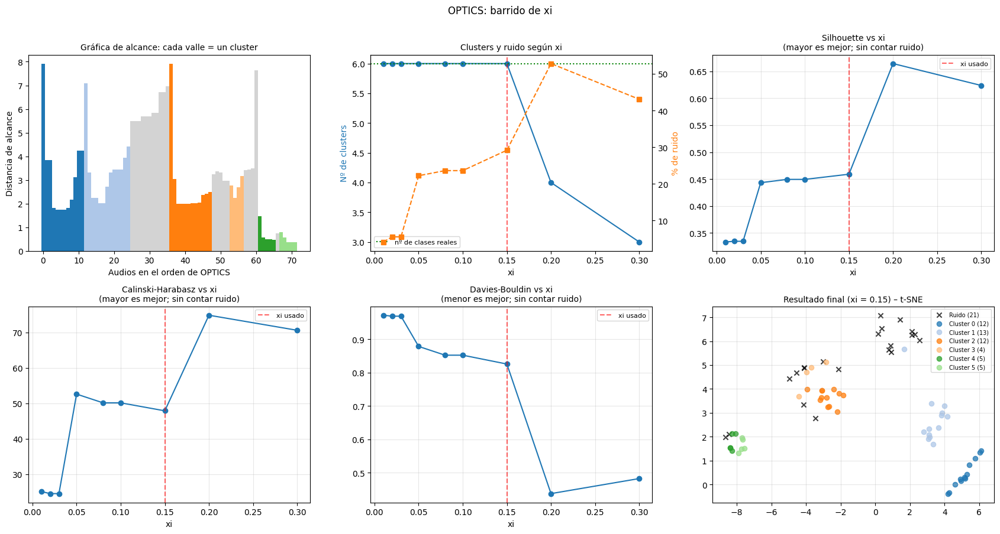

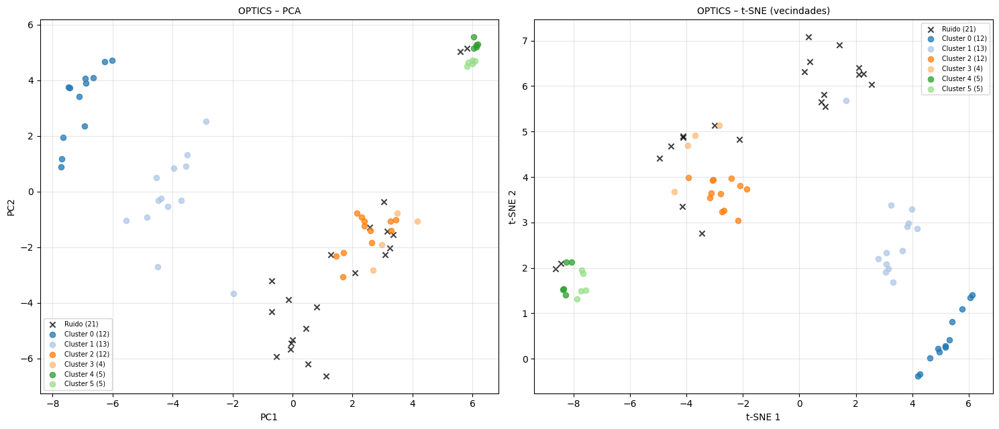

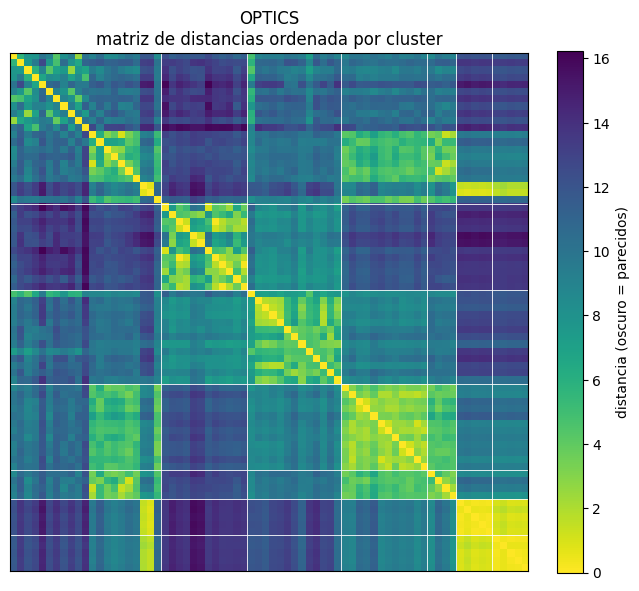

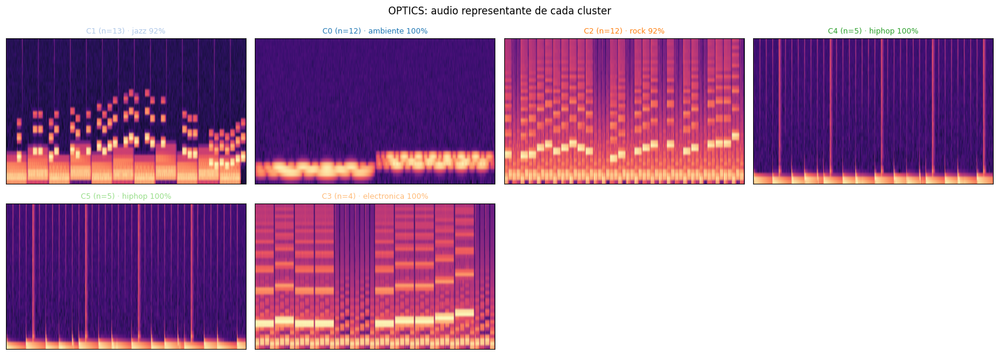

▶ OPTICS – Cluster 1 (n=13) · jazz 92% – jazz/jazz_006.wav


▶ OPTICS – Cluster 0 (n=12) · ambiente 100% – ambiente/ambiente_007.wav


▶ OPTICS – Cluster 2 (n=12) · rock 92% – rock/rock_006.wav


▶ OPTICS – Cluster 4 (n=5) · hiphop 100% – hiphop/hiphop_004.wav


OPTICS: 21 audios atípicos. Se muestran 6:


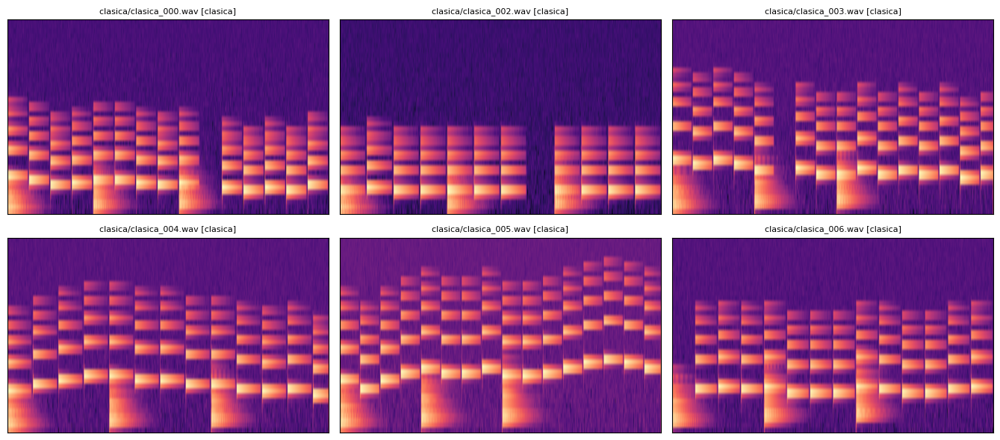

▶ clasica/clasica_000.wav


▶ clasica/clasica_002.wav


▶ clasica/clasica_003.wav


In [14]:
optics = OPTICS(min_samples=MIN_SAMPLES, xi=0.05, min_cluster_size=OPT_MIN_CLUSTER_SIZE).fit(Xc)
def etiquetas_xi(xi):
    return cluster_optics_xi(reachability=optics.reachability_, predecessor=optics.predecessor_, ordering=optics.ordering_,
                             min_samples=MIN_SAMPLES, min_cluster_size=OPT_MIN_CLUSTER_SIZE, xi=xi)[0]
xi_grid = [0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.30]
df_xi = barrido(xi_grid, etiquetas_xi)
xi_op, origen = elegir(df_xi, XI_ELEGIDO, 0.05, "valor por defecto"); xi_op = float(xi_op)
print(f"xi usado: {xi_op} ({origen})")

etiquetas_op = etiquetas_xi(xi_op)
print(f"OPTICS: {len(set(etiquetas_op[etiquetas_op != -1]))} clusters y {(etiquetas_op == -1).sum()} audios de ruido ({(etiquetas_op == -1).mean():.1%}).")

def extra_optics(ax):
    o = optics.ordering_; r = optics.reachability_[o].copy(); r[~np.isfinite(r)] = np.nanmax(r[np.isfinite(r)])
    ax.bar(np.arange(len(r)), r, width=1.0, color=[color_cluster(k) if k != -1 else "lightgray" for k in etiquetas_op[o]])
    ax.set_title("Gráfica de alcance: cada valle = un cluster", fontsize=10); ax.set_xlabel("Audios en el orden de OPTICS"); ax.set_ylabel("Distancia de alcance")

graficar_barrido(df_xi, "xi", xi_op, "OPTICS: barrido de xi", "24_optics_barrido.png", extra_optics, etiquetas_op)
graficar_2d(etiquetas_op, "OPTICS", "25_optics_2d.png")
graficar_matriz_dist(etiquetas_op, "OPTICS", "26_optics_dist.png")
mostrar_representantes(etiquetas_op, "OPTICS", "27_optics_repr.png")
mostrar_atipicos(etiquetas_op, "OPTICS")

## 12) Comparación de los 5 modelos
**Métricas internas** (no necesitan etiquetas): Silhouette, Calinski-Harabasz, Davies-Bouldin, estabilidad (ARI en remuestreos), cobertura y balance.
**Métricas externas** (solo si hay etiquetas reales): ARI, NMI, homogeneidad (cada cluster tiene una sola clase), completitud (cada clase cae en un solo cluster), V-measure y pureza. Las externas son la mejor prueba de "¿agrupó como lo haría una persona?".

In [15]:
def estabilidad(ajustar, X_, lab_full, n_rep=N_BOOT, frac=0.8, seed=0):
    rng = np.random.default_rng(seed); aris = []
    for _ in range(n_rep):
        idx = rng.choice(len(X_), int(frac * len(X_)), replace=False)
        aris.append(adjusted_rand_score(lab_full[idx], ajustar(X_[idx])))
    return float(np.mean(aris)), float(np.std(aris))

def pureza(lab):
    m = lab != -1
    return sum(Counter(y_real[lab == k]).most_common(1)[0][1] for k in set(lab[m])) / len(lab) if m.any() else 0.0

ajustadores = {
    "Jerárquico (Ward)": lambda X_: AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_),
    "K-Means": lambda X_: KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X_),
    "DBSCAN": lambda X_: DBSCAN(eps=eps_db, min_samples=MIN_SAMPLES).fit_predict(X_),
    "HDBSCAN": lambda X_: HDBSCAN(min_cluster_size=mcs_h, min_samples=HDB_MIN_SAMPLES).fit_predict(X_),
    "OPTICS": lambda X_: OPTICS(min_samples=MIN_SAMPLES, xi=xi_op, min_cluster_size=OPT_MIN_CLUSTER_SIZE).fit_predict(X_),
}
resultados = {"Jerárquico (Ward)": etiquetas_jer, "K-Means": etiquetas_km, "DBSCAN": etiquetas_db, "HDBSCAN": etiquetas_hdb, "OPTICS": etiquetas_op}

filas = {}
for nombre, lab in resultados.items():
    print("Calculando", nombre, "...")
    est_m, est_s = estabilidad(ajustadores[nombre], Xc, lab); tam = pd.Series(lab[lab != -1]).value_counts()
    fila = {"n_clusters": len(set(lab[lab != -1])), "ruido_%": 100 * (lab == -1).mean(), "cobertura": (lab != -1).mean(),
            "cluster_mayor_%": 100 * tam.max() / len(lab) if len(tam) else np.nan, **metricas_internas(Xc, lab),
            "estabilidad_ARI": est_m, "estabilidad_std": est_s}
    if TIENE_REAL:
        fila.update({"ARI_real": adjusted_rand_score(y_real, lab), "NMI_real": normalized_mutual_info_score(y_real, lab),
                     "homogeneidad": homogeneity_score(y_real, lab), "completitud": completeness_score(y_real, lab),
                     "V_measure": v_measure_score(y_real, lab), "pureza": pureza(lab)})
    filas[nombre] = fila
df_comp = pd.DataFrame(filas).T
print("\nTabla comparativa (métricas internas sin contar el ruido):"); display(df_comp.round(3))
df_comp.to_csv(os.path.join(RESULTADOS, "comparacion_algoritmos.csv"))

Calculando Jerárquico (Ward) ...
Calculando K-Means ...
Calculando DBSCAN ...
Calculando HDBSCAN ...
Calculando OPTICS ...

Tabla comparativa (métricas internas sin contar el ruido):


,n_clusters,ruido_%,cobertura,cluster_mayor_%,silhouette,calinski,davies_bouldin,estabilidad_ARI,estabilidad_std,ARI_real,NMI_real,homogeneidad,completitud,V_measure,pureza
Jerárquico (Ward),8.0,0.000,1.000,33.333,0.536,47.301,0.837,0.832,0.121,0.680,0.839,0.844,0.834,0.839,0.819
K-Means,8.0,0.000,1.000,33.333,0.528,48.299,0.843,0.749,0.109,0.671,0.854,0.871,0.838,0.854,0.833
DBSCAN,5.0,38.889,0.611,16.667,0.635,140.544,0.594,0.818,0.134,0.497,0.729,0.697,0.765,0.729,0.611
HDBSCAN,4.0,18.056,0.819,33.333,0.591,86.445,0.690,0.789,0.077,0.729,0.857,0.800,0.921,0.857,0.639
OPTICS,6.0,29.167,0.708,18.056,0.459,47.902,0.826,0.602,0.132,0.628,0.770,0.771,0.769,0.770,0.681


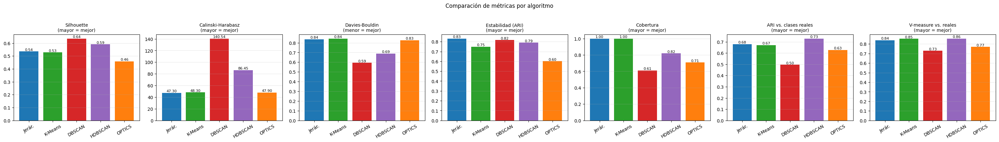

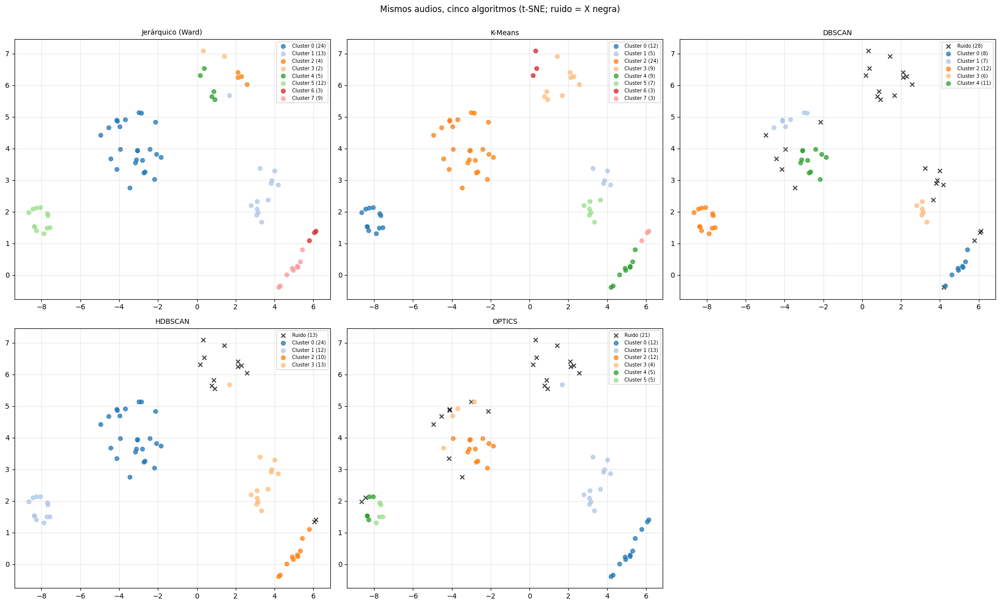

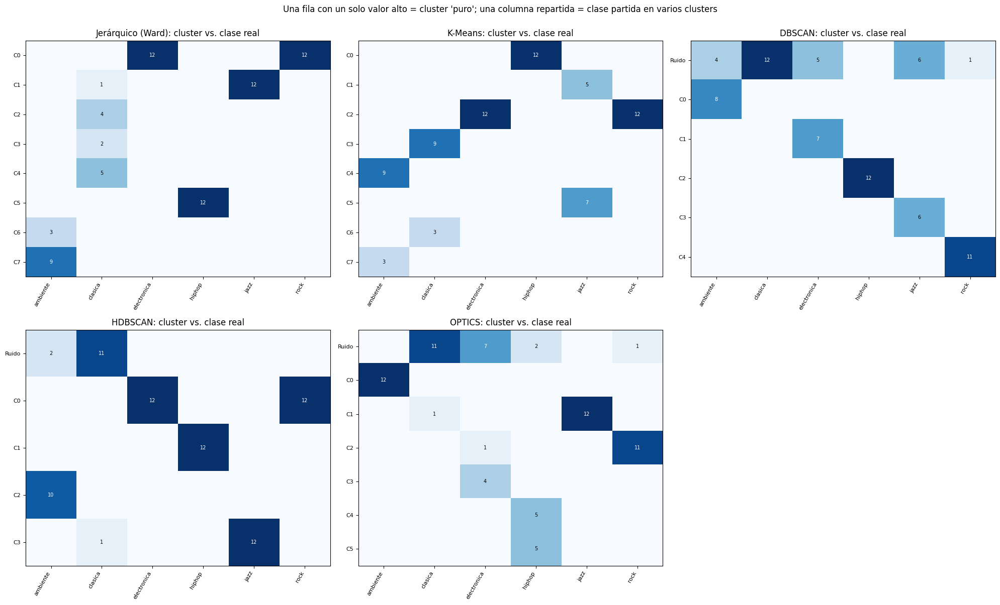

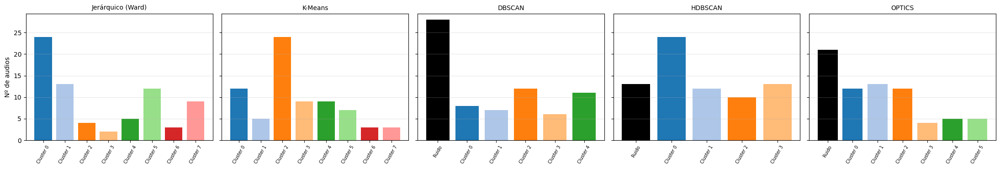

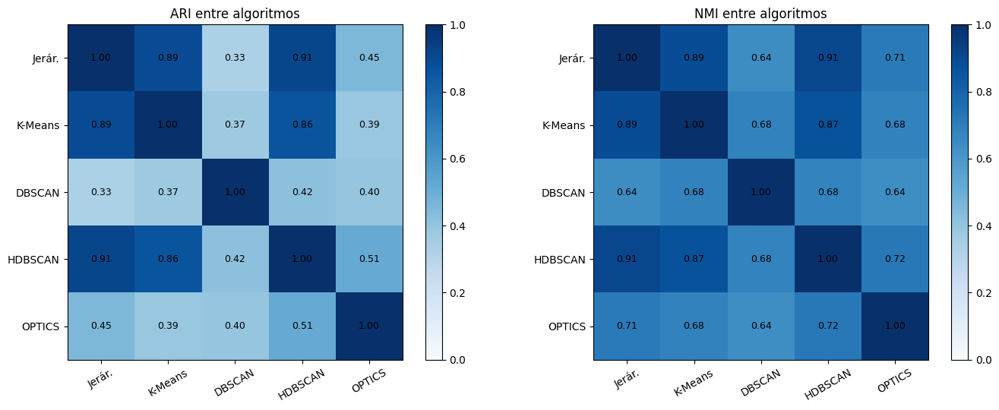

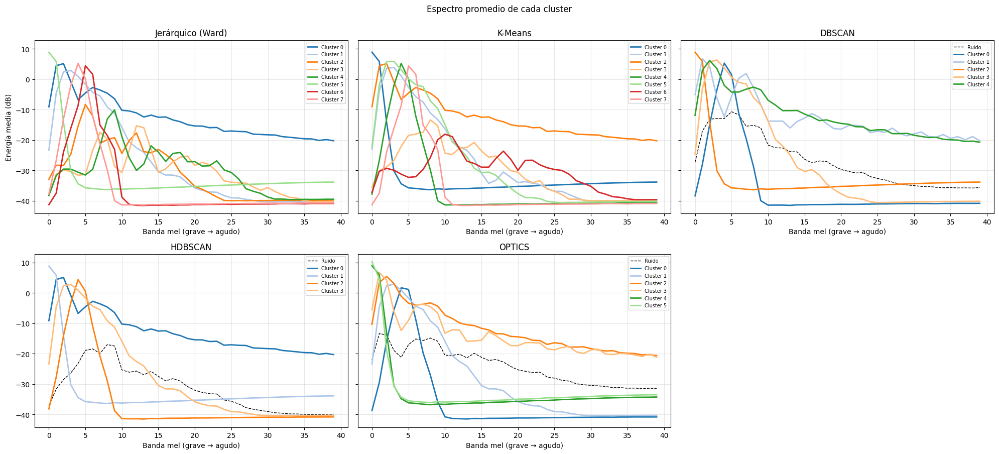

In [16]:
nombres_alg = list(resultados); na = len(nombres_alg)
corto = {"Jerárquico (Ward)": "Jerár.", "K-Means": "K-Means", "DBSCAN": "DBSCAN", "HDBSCAN": "HDBSCAN", "OPTICS": "OPTICS"}
col_alg = {"Jerárquico (Ward)": "tab:blue", "K-Means": "tab:green", "DBSCAN": "tab:red", "HDBSCAN": "tab:purple", "OPTICS": "tab:orange"}

# ---- (a) Barras de métricas ----
barras = [("silhouette", "Silhouette\n(mayor = mejor)"), ("calinski", "Calinski-Harabasz\n(mayor = mejor)"), ("davies_bouldin", "Davies-Bouldin\n(menor = mejor)"),
          ("estabilidad_ARI", "Estabilidad (ARI)\n(mayor = mejor)"), ("cobertura", "Cobertura\n(mayor = mejor)")]
if TIENE_REAL: barras += [("ARI_real", "ARI vs. clases reales\n(mayor = mejor)"), ("V_measure", "V-measure vs. reales\n(mayor = mejor)")]
fig, axs = plt.subplots(1, len(barras), figsize=(4.4 * len(barras), 4.2))
for ax, (col, titulo) in zip(axs, barras):
    vals = df_comp[col].astype(float).values
    ax.bar(range(na), np.nan_to_num(vals), color=[col_alg[nm] for nm in nombres_alg])
    for i, v in enumerate(vals): ax.text(i, 0 if np.isnan(v) else v, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(na)); ax.set_xticklabels([corto[nm] for nm in nombres_alg], rotation=30); ax.set_title(titulo, fontsize=10); ax.grid(alpha=.3, axis="y")
plt.suptitle("Comparación de métricas por algoritmo", y=1.03); plt.tight_layout(); guardar("28_comparacion_metricas.png"); plt.show()

# ---- (b) Los cinco clusterings en t-SNE ----
fig, axs = plt.subplots(2, 3, figsize=(20, 12))
for ax, nombre in zip(axs.flatten(), nombres_alg): dibujar_2d(ax, T2, resultados[nombre], nombre)
for ax in axs.flatten()[na:]: ax.axis("off")
plt.suptitle("Mismos audios, cinco algoritmos (t-SNE; ruido = X negra)", y=1.0); plt.tight_layout(); guardar("29_comparacion_tsne.png"); plt.show()

# ---- (c) Matriz de contingencia: ¿qué clase real cae en cada cluster? ----
if TIENE_REAL:
    fig, axs = plt.subplots(2, 3, figsize=(20, 12))
    for ax, nombre in zip(axs.flatten(), nombres_alg):
        tabla = pd.crosstab(pd.Series(resultados[nombre], name="cluster"), pd.Series(y_real, name="clase real"))
        im = ax.imshow(tabla.values, cmap="Blues", aspect="auto")
        ax.set_xticks(range(tabla.shape[1])); ax.set_xticklabels(tabla.columns, rotation=60, ha="right", fontsize=8)
        ax.set_yticks(range(tabla.shape[0])); ax.set_yticklabels(["Ruido" if k == -1 else f"C{k}" for k in tabla.index], fontsize=8)
        if tabla.size <= 400:
            for i in range(tabla.shape[0]):
                for j in range(tabla.shape[1]):
                    if tabla.values[i, j]: ax.text(j, i, tabla.values[i, j], ha="center", va="center", fontsize=7, color="white" if tabla.values[i, j] > tabla.values.max() / 2 else "black")
        ax.set_title(f"{nombre}: cluster vs. clase real")
    for ax in axs.flatten()[na:]: ax.axis("off")
    plt.suptitle("Una fila con un solo valor alto = cluster 'puro'; una columna repartida = clase partida en varios clusters", y=1.0)
    plt.tight_layout(); guardar("30_contingencia.png"); plt.show()

# ---- (d) Tamaño de clusters y acuerdo entre algoritmos ----
fig, axs = plt.subplots(1, 5, figsize=(22, 3.8), sharey=True)
for ax, nombre in zip(axs, nombres_alg):
    vc = pd.Series(resultados[nombre]).value_counts().sort_index()
    ax.bar([nombre_cluster(k) for k in vc.index], vc.values, color=[color_cluster(k) for k in vc.index]); ax.set_title(nombre, fontsize=10)
    ax.tick_params(axis="x", rotation=60, labelsize=7); ax.grid(alpha=.3, axis="y")
axs[0].set_ylabel("Nº de audios"); plt.tight_layout(); plt.show()

ari = pd.DataFrame(index=nombres_alg, columns=nombres_alg, dtype=float); nmi = ari.copy()
for a in nombres_alg:
    for b in nombres_alg:
        ari.loc[a, b] = adjusted_rand_score(resultados[a], resultados[b]); nmi.loc[a, b] = normalized_mutual_info_score(resultados[a], resultados[b])
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, mat, titulo in [(axs[0], ari, "ARI entre algoritmos"), (axs[1], nmi, "NMI entre algoritmos")]:
    im_ = ax.imshow(mat.values.astype(float), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(na)); ax.set_xticklabels([corto[nm] for nm in nombres_alg], rotation=30); ax.set_yticks(range(na)); ax.set_yticklabels([corto[nm] for nm in nombres_alg])
    for i in range(na):
        for j in range(na): ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(titulo); plt.colorbar(im_, ax=ax, fraction=.046)
plt.tight_layout(); guardar("31_acuerdo_algoritmos.png"); plt.show()

# ---- (e) Espectro medio por cluster (¿en qué frecuencias se diferencian?) ----
MELMEDIA = np.array([L_.mean(1) for L_ in MELS])
fig, axs = plt.subplots(2, 3, figsize=(20, 9), sharey=True)
for ax, nombre in zip(axs.flatten(), nombres_alg):
    lab = resultados[nombre]
    for k in sorted(set(lab))[:14]: ax.plot(MELMEDIA[lab == k].mean(0), color=color_cluster(k), label=nombre_cluster(k), lw=2 if k != -1 else 1, ls="--" if k == -1 else "-")
    ax.set_title(nombre); ax.set_xlabel("Banda mel (grave → agudo)"); ax.grid(alpha=.3)
    if len(set(lab)) <= 12: ax.legend(fontsize=7)
axs[0, 0].set_ylabel("Energía media (dB)")
for ax in axs.flatten()[na:]: ax.axis("off")
plt.suptitle("Espectro promedio de cada cluster", y=1.0); plt.tight_layout(); guardar("32_espectro_por_cluster.png"); plt.show()

Puesto por criterio (1 = mejor):


,silhouette,calinski,davies_bouldin,estabilidad_ARI,cobertura,ARI_real,V_measure,puesto_promedio
HDBSCAN,2.0,2.0,2.0,3.0,3.0,1.0,1.0,2.00
Jerárquico (Ward),3.0,5.0,4.0,1.0,1.0,2.0,3.0,2.71
DBSCAN,1.0,1.0,1.0,2.0,5.0,5.0,5.0,2.86
K-Means,4.0,3.0,5.0,4.0,1.0,3.0,2.0,3.14
OPTICS,5.0,4.0,3.0,5.0,4.0,4.0,4.0,4.14



>>> Mejor algoritmo según el puesto promedio: HDBSCAN
>>> Mejor según ARI contra las clases reales: HDBSCAN


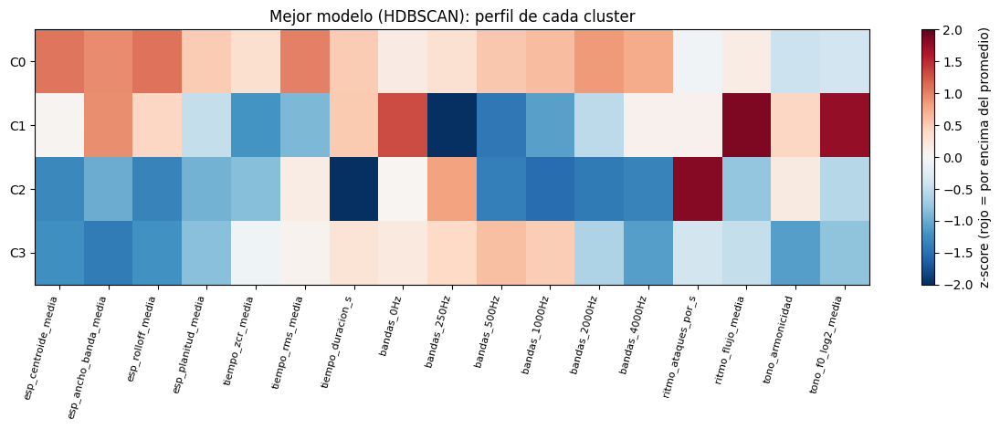

In [17]:
# ---------------- Ranking y criterio automático ----------------
criterios = {"silhouette": True, "calinski": True, "davies_bouldin": False, "estabilidad_ARI": True, "cobertura": True}
if TIENE_REAL: criterios.update({"ARI_real": True, "V_measure": True})
ranking = pd.DataFrame({c: df_comp[c].astype(float).rank(ascending=not mayor, method="min", na_option="bottom") for c, mayor in criterios.items()})
ranking["puesto_promedio"] = ranking.mean(axis=1); ranking = ranking.sort_values("puesto_promedio")
print("Puesto por criterio (1 = mejor):"); display(ranking.round(2))
print(f"\n>>> Mejor algoritmo según el puesto promedio: {ranking.index[0]}")
if TIENE_REAL: print(f">>> Mejor según ARI contra las clases reales: {df_comp['ARI_real'].astype(float).idxmax()}")
for nombre in nombres_alg:
    r = df_comp.loc[nombre]
    if r["ruido_%"] > 100 * MAX_RUIDO: print(f"⚠ {nombre} dejó {r['ruido_%']:.0f} % de los audios como ruido: sus métricas internas son poco comparables.")
    if r["cluster_mayor_%"] > 80: print(f"⚠ {nombre} metió >80 % de los audios en un solo cluster: casi no separa.")
    if r["n_clusters"] < 2: print(f"⚠ {nombre} produjo menos de 2 clusters; revisa sus parámetros.")
mejor = ranking.index[0]
graficar_perfil(resultados[mejor], f"Mejor modelo ({mejor})", "33_perfil_mejor.png")

## 13) Exportar resultados

In [18]:
salida = pd.DataFrame({"audio": nombres})
if TIENE_REAL: salida["clase_real"] = y_real
for nombre, lab in resultados.items(): salida[f"cluster_{corto[nombre].lower().replace('.', '')}"] = lab
salida["hdbscan_prob"] = hdb.probabilities_
salida.to_csv(os.path.join(RESULTADOS, "resultados_clusters_audio.csv"), index=False)
df.assign(**{f"cluster_{corto[nm]}": lab for nm, lab in resultados.items()}).to_csv(os.path.join(RESULTADOS, "caracteristicas_y_clusters.csv"))
print("Guardado en:", RESULTADOS); salida.head(10)

Guardado en: resultados_musica


,audio,clase_real,cluster_jerár,cluster_k-means,cluster_dbscan,cluster_hdbscan,cluster_optics,hdbscan_prob
0,ambiente/ambiente_000.wav,ambiente,7,4,0,2,0,1.000000
1,ambiente/ambiente_001.wav,ambiente,6,7,-1,2,0,0.984896
2,ambiente/ambiente_002.wav,ambiente,7,4,0,2,0,1.000000
3,ambiente/ambiente_003.wav,ambiente,7,4,0,2,0,1.000000
4,ambiente/ambiente_004.wav,ambiente,6,7,-1,-1,0,0.000000
5,ambiente/ambiente_005.wav,ambiente,6,7,-1,-1,0,0.000000
6,ambiente/ambiente_006.wav,ambiente,7,4,-1,2,0,0.906750
7,ambiente/ambiente_007.wav,ambiente,7,4,0,2,0,1.000000
8,ambiente/ambiente_008.wav,ambiente,7,4,0,2,0,1.000000
9,ambiente/ambiente_009.wav,ambiente,7,4,0,2,0,1.000000


# PARTE B — Fourier y la huella de Shazam
Hasta aquí usamos Fourier "por dentro" (el espectrograma de la sección 2). Ahora lo ponemos al centro y construimos un **mini-Shazam**: dada una **muestra corta y con ruido**, decir **de cuál canción** viene.

### Cómo funciona Shazam (en 4 pasos)
1. **FFT por ventanas → espectrograma.** Cada instante se descompone en frecuencias: ¿qué notas suenan ahora?
2. **Constelación:** de todo el espectrograma se guardan **solo los picos** (puntos más fuertes que sus vecinos). Los picos sobreviven al ruido y a la compresión mp3 porque son lo más intenso.
3. **Hashes:** se unen picos cercanos en pares `(frecuencia1, frecuencia2, Δtiempo)`. Un par es una "palabra" muy específica de esa canción y no depende de en qué segundo empiece la muestra.
4. **Votación:** los hashes de la muestra se buscan en la base de datos. Si la canción es la correcta, **todos los aciertos coinciden en el mismo desfase de tiempo** (`t_canción − t_muestra`), y eso forma un pico enorme en el histograma.

> Diferencia con la Parte A: el clustering usa un **resumen** del espectro para decir *"suenan parecido"*; Shazam usa los **picos exactos** para decir *"es exactamente esta grabación"*. Dos canciones distintas del mismo género se agrupan en A, pero Shazam jamás las confunde.


## B1) Fourier en una imagen: qué hace la FFT
Una señal es una **suma de ondas senoidales**. La FFT las separa y dice "hay 440 Hz con amplitud 1, 880 Hz con 0,5...". Abajo: tres notas mezcladas en el tiempo (izquierda) y su espectro (derecha). Después, el **compromiso tiempo-frecuencia** con una canción real: ventana corta = sabes *cuándo* pero no *qué nota*; ventana larga = al revés.

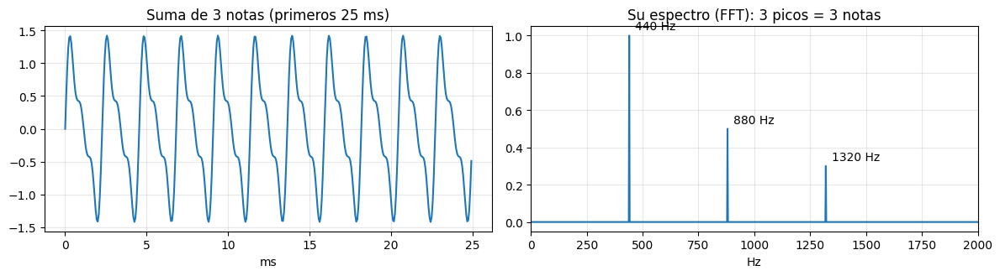

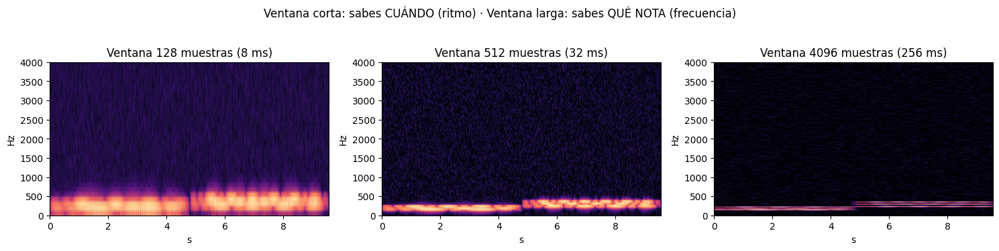

In [19]:
t = np.arange(0, 1.0, 1 / SR)
mezcla = 1.0 * np.sin(2 * np.pi * 440 * t) + 0.5 * np.sin(2 * np.pi * 880 * t) + 0.3 * np.sin(2 * np.pi * 1320 * t)
esp = np.abs(np.fft.rfft(mezcla * np.hanning(len(mezcla)))) / (len(t) / 4); fq = np.fft.rfftfreq(len(t), 1 / SR)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(t[:400] * 1000, mezcla[:400]); ax[0].set_title("Suma de 3 notas (primeros 25 ms)"); ax[0].set_xlabel("ms"); ax[0].grid(alpha=.3)
ax[1].plot(fq, esp); ax[1].set_xlim(0, 2000); ax[1].set_title("Su espectro (FFT): 3 picos = 3 notas"); ax[1].set_xlabel("Hz"); ax[1].grid(alpha=.3)
for f_, a_ in [(440, 1), (880, .5), (1320, .3)]: ax[1].annotate(f"{f_} Hz", (f_, a_), textcoords="offset points", xytext=(5, 5))
plt.tight_layout(); guardar("B1_fourier_suma_de_senos.png"); plt.show()
display(Audio(mezcla, rate=SR))

# Compromiso tiempo-frecuencia sobre la primera canción
cancion = senales[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, nf in zip(ax, (128, 512, 4096)):
    hop = nf // 2; w = np.hanning(nf)
    fr_ = cancion[np.arange(nf)[None, :] + hop * np.arange(1 + (len(cancion) - nf) // hop)[:, None]]
    Sx = 20 * np.log10(np.abs(np.fft.rfft(fr_ * w, axis=1)).T + 1e-6)
    a.imshow(Sx, origin="lower", aspect="auto", cmap="magma", vmin=Sx.max() - 70, extent=[0, len(cancion) / SR, 0, SR / 2])
    a.set_ylim(0, 4000); a.set_title(f"Ventana {nf} muestras ({nf / SR * 1000:.0f} ms)"); a.set_xlabel("s"); a.set_ylabel("Hz")
plt.suptitle("Ventana corta: sabes CUÁNDO (ritmo) · Ventana larga: sabes QUÉ NOTA (frecuencia)", y=1.03); plt.tight_layout(); guardar("B1_tiempo_vs_frecuencia.png"); plt.show()

## B2) Constelación de picos y huellas (hashes)
Se calcula el espectrograma con ventana de 256 ms (por debajo de 3 kHz), se buscan los **máximos locales** (un punto es pico si es el más fuerte en su vecindario de `VECINDAD`) y se descartan los débiles. Después cada pico (ancla) se une con los siguientes `FAN_OUT` picos que caen dentro de una ventana de tiempo, generando hashes `(f1, f2, Δt)`.

Base de datos: 72 canciones | 156,220 huellas | 64,744 hashes distintos | ~2170 huellas por canción


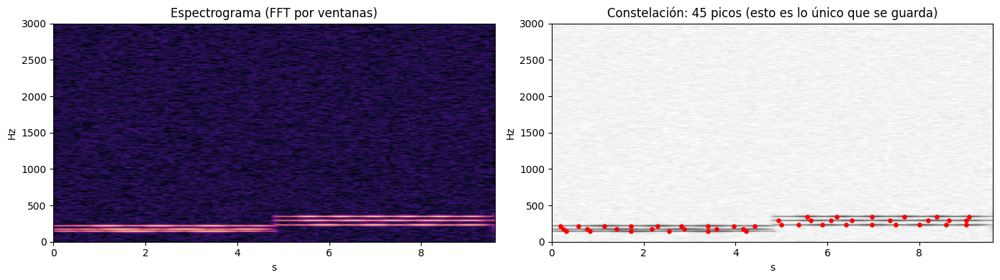

El espectrograma tiene 115,200 números; la constelación guarda solo 45 puntos (0.039%).


In [20]:
from scipy.ndimage import maximum_filter

FP_NFFT, FP_HOP = 4096, 1024         # ventana de 256 ms (resolución fina en frecuencia), salto de 64 ms
FMAX_FP   = 3000                     # solo se buscan picos por debajo de 3 kHz (el ruido blanco domina arriba)
VECINDAD  = (11, 7)                  # (bins de frecuencia, frames de tiempo) para ser "pico local"
UMBRAL_DB = 35                       # un pico debe estar a menos de 35 dB del máximo de la canción
FAN_OUT   = 12                       # cada ancla se une con los siguientes 12 picos
DT_MIN, DT_MAX = 1, 20               # rango (frames) del par ancla -> objetivo
FQ_BIN    = 2                        # cuantización de frecuencia del hash (más grande = más tolerante, menos específico)

VENT_FP = np.hanning(FP_NFFT)
def espectro_fp(y):
    yp = np.pad(y, (FP_NFFT // 2, FP_NFFT // 2), mode="reflect")
    nf = 1 + (len(yp) - FP_NFFT) // FP_HOP
    fr_ = yp[np.arange(FP_NFFT)[None, :] + FP_HOP * np.arange(nf)[:, None]]
    S_ = 20 * np.log10(np.abs(np.fft.rfft(fr_ * VENT_FP, axis=1)).T + 1e-6)       # (frecuencia x tiempo) en dB
    return S_[: int(FMAX_FP / (SR / FP_NFFT))]

def constelacion(y):
    Sdb = espectro_fp(y)
    es_pico = (maximum_filter(Sdb, size=VECINDAD) == Sdb) & (Sdb > Sdb.max() - UMBRAL_DB)
    f_idx, t_idx = np.where(es_pico); orden = np.argsort(t_idx, kind="stable")
    return f_idx[orden], t_idx[orden], Sdb

def huellas(f_idx, t_idx):
    out = []
    for i in range(len(t_idx)):
        for j in range(i + 1, min(i + 1 + FAN_OUT, len(t_idx))):
            dt = t_idx[j] - t_idx[i]
            if DT_MIN <= dt <= DT_MAX: out.append(((int(f_idx[i]) // FQ_BIN, int(f_idx[j]) // FQ_BIN, int(dt)), int(t_idx[i])))
    return out

# --- Base de datos: hash -> lista de (id_cancion, t_ancla) ---
BD = {}; n_huellas = []
for cid, y in enumerate(senales):
    f_, t_, _ = constelacion(y); hs = huellas(f_, t_); n_huellas.append(len(hs))
    for h, ta in hs: BD.setdefault(h, []).append((cid, ta))
print(f"Base de datos: {len(senales)} canciones | {sum(n_huellas):,} huellas | {len(BD):,} hashes distintos | ~{np.mean(n_huellas):.0f} huellas por canción")

# --- Visualizar la constelación de una canción ---
ej = 0; f_, t_, Sdb = constelacion(senales[ej])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ext = [0, Sdb.shape[1] * FP_HOP / SR, 0, FMAX_FP]
ax[0].imshow(Sdb, origin="lower", aspect="auto", cmap="magma", vmin=Sdb.max() - 80, extent=ext); ax[0].set_title("Espectrograma (FFT por ventanas)")
ax[1].imshow(Sdb, origin="lower", aspect="auto", cmap="Greys", vmin=Sdb.max() - 80, vmax=Sdb.max() + 20, extent=ext)
ax[1].scatter(t_ * FP_HOP / SR, f_ * SR / FP_NFFT, s=14, c="red")
ax[1].set_title(f"Constelación: {len(t_)} picos (esto es lo único que se guarda)")
for a in ax: a.set_xlabel("s"); a.set_ylabel("Hz")
plt.tight_layout(); guardar("B2_constelacion.png"); plt.show()
print(f"El espectrograma tiene {Sdb.size:,} números; la constelación guarda solo {len(t_)} puntos ({len(t_) / Sdb.size:.3%}).")

## B3) Identificar una muestra con ruido
Se toma un **trozo aleatorio de `DUR_MUESTRA` segundos** de una canción, se le **suma ruido** a un nivel de SNR dado y se busca en la base. Para cada canción candidata se cuenta cuántos hashes coinciden *con el mismo desfase*; la ganadora es la del mayor conteo. El histograma de desfases muestra por qué funciona: la canción correcta tiene un pico enorme; las demás, ruido disperso.

Canción real: electronica/electronica_003.wav  (la muestra empieza en 6.9 s)
Shazam dice:  electronica/electronica_003.wav  con 49 hashes alineados  -> ✔ correcto


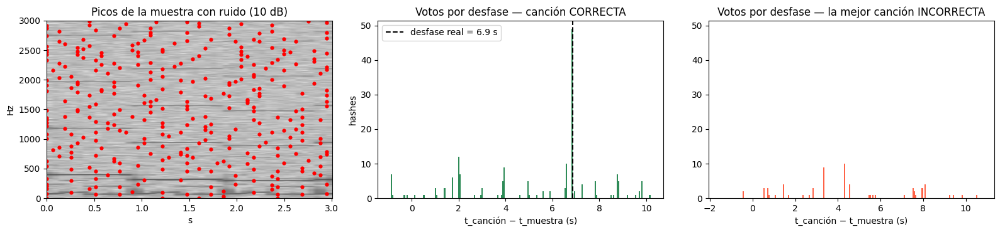

In [21]:
DUR_MUESTRA = 3.0       # segundos de la muestra
rng_b = np.random.default_rng(SEMILLA)

def agregar_ruido(y, snr_db, rng):
    if snr_db is None: return y
    p = np.mean(y ** 2); ruido = rng.standard_normal(len(y)) * np.sqrt(p / 10 ** (snr_db / 10)); return (y + ruido).astype(np.float32)

def identificar(muestra):
    f_, t_, _ = constelacion(muestra); votos = {}
    for h, tq in huellas(f_, t_):
        for cid, tb in BD.get(h, ()):
            votos.setdefault(cid, Counter())[tb - tq] += 1
    if not votos: return None, 0, {}
    puntaje = {cid: c.most_common(1)[0][1] for cid, c in votos.items()}
    mejor = max(puntaje, key=puntaje.get); return mejor, puntaje[mejor], votos

# --- Ejemplo detallado: un trozo al azar con ruido a 10 dB (la música es 10 veces más potente que el ruido) ---
ricas = np.where(np.array(n_huellas) >= np.median(n_huellas))[0]      # para el ejemplo, canciones con constelación rica (las dispersas, como 'ambiente', son más difíciles: ver tabla)
cid = int(rng_b.choice(ricas)); L = int(DUR_MUESTRA * SR); ini = int(rng_b.integers(0, len(senales[cid]) - L))
SNR_EJEMPLO = 10
muestra = agregar_ruido(senales[cid][ini:ini + L], SNR_EJEMPLO, rng_b)
pred, pts, votos = identificar(muestra)
print(f"Canción real: {nombres[cid]}  (la muestra empieza en {ini / SR:.1f} s)")
print(f"Shazam dice:  {nombres[pred] if pred is not None else '—'}  con {pts} hashes alineados  -> {'✔ correcto' if pred == cid else '✘ falló'}")
display(Audio(muestra, rate=SR))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
fm, tm, Sm = constelacion(muestra)
ax[0].imshow(Sm, origin="lower", aspect="auto", cmap="Greys", vmin=Sm.max() - 80, vmax=Sm.max() + 20, extent=[0, Sm.shape[1] * FP_HOP / SR, 0, FMAX_FP])
ax[0].scatter(tm * FP_HOP / SR, fm * SR / FP_NFFT, s=12, c="red"); ax[0].set_title(f"Picos de la muestra con ruido ({SNR_EJEMPLO} dB)")
ax[0].set_xlabel("s"); ax[0].set_ylabel("Hz")
if cid in votos:
    off = np.array(list(votos[cid].elements())) * FP_HOP / SR
    ax[1].hist(off, bins=200, color="seagreen"); ax[1].axvline(ini / SR, color="k", ls="--", label=f"desfase real = {ini / SR:.1f} s"); ax[1].legend()
ax[1].set_title("Votos por desfase — canción CORRECTA"); ax[1].set_xlabel("t_canción − t_muestra (s)"); ax[1].set_ylabel("hashes")
otro = [c for c in votos if c != cid]
if otro:
    c2 = max(otro, key=lambda c: sum(votos[c].values())); off2 = np.array(list(votos[c2].elements())) * FP_HOP / SR
    ax[2].hist(off2, bins=200, color="tomato", range=ax[1].get_xlim() if cid in votos else None)
ax[2].set_title("Votos por desfase — la mejor canción INCORRECTA"); ax[2].set_xlabel("t_canción − t_muestra (s)")
ax[2].set_ylim(0, ax[1].get_ylim()[1] if cid in votos else None)
plt.tight_layout(); guardar("B3_votacion_desfase.png"); plt.show()

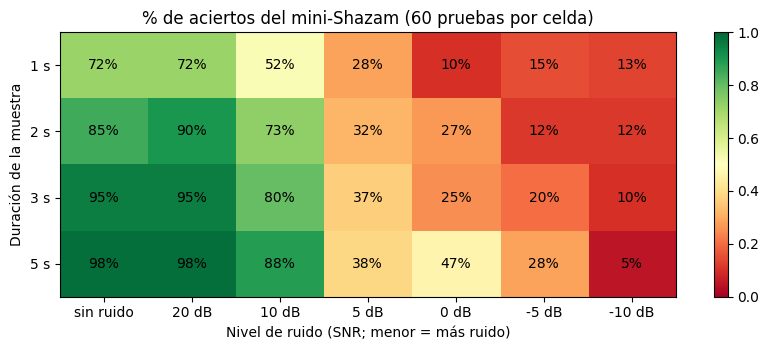

In [22]:
# --- Precisión vs. ruido y vs. duración de la muestra ---
niveles = [None, 20, 10, 5, 0, -5, -10]; duraciones = [1.0, 2.0, 3.0, 5.0]; N_PRUEBAS = min(60, 2 * len(senales))
tabla = pd.DataFrame(index=[f"{d:g} s" for d in duraciones], columns=["sin ruido" if s is None else f"{s} dB" for s in niveles], dtype=float)
rng_t = np.random.default_rng(SEMILLA + 1)
for d in duraciones:
    Ld = int(d * SR)
    for s in niveles:
        ok = 0
        for _ in range(N_PRUEBAS):
            c = int(rng_t.integers(len(senales))); y_ = senales[c]
            if len(y_) <= Ld: continue
            i0 = int(rng_t.integers(0, len(y_) - Ld)); m = agregar_ruido(y_[i0:i0 + Ld], s, rng_t)
            ok += identificar(m)[0] == c
        tabla.loc[f"{d:g} s", "sin ruido" if s is None else f"{s} dB"] = ok / N_PRUEBAS
fig, ax = plt.subplots(figsize=(8.5, 3.6)); im = ax.imshow(tabla.values.astype(float), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(tabla.columns))); ax.set_xticklabels(tabla.columns); ax.set_yticks(range(len(tabla))); ax.set_yticklabels(tabla.index)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]): ax.text(j, i, f"{tabla.values[i, j]:.0%}", ha="center", va="center")
ax.set_xlabel("Nivel de ruido (SNR; menor = más ruido)"); ax.set_ylabel("Duración de la muestra"); ax.set_title(f"% de aciertos del mini-Shazam ({N_PRUEBAS} pruebas por celda)")
plt.colorbar(im); plt.tight_layout(); guardar("B3_precision_vs_ruido.png"); plt.show()

> **Cómo leer la tabla:** más segundos y menos ruido = más aciertos. Con ruido muy fuerte (≤ 0 dB) falla bastante: el ruido blanco tapa las notas suaves, sobre todo en canciones con pocos picos (`ambiente`, `clasica`). Shazam real aguanta más porque la música real tiene muchos más picos y usa muestras de 10 s o más.

## B4) ¿Para qué sirve esto junto al clustering?
- **Shazam (B)** responde *"¿es la misma grabación?"*. Sirve para **detectar duplicados o copias** en tu playlist, aunque estén recortadas, con otra calidad o con ruido.
- **Clustering (A)** responde *"¿suena parecido?"*: géneros, estados de ánimo, instrumentos.
- **Combinados:** primero se eliminan duplicados con huellas (si no, un mismo tema repetido forma un "cluster falso" muy denso en DBSCAN/HDBSCAN) y después se agrupa. La celda de abajo busca pares de canciones que comparten muchos hashes alineados.

In [23]:
# Pares de canciones que comparten muchas huellas alineadas = posibles duplicados / copias
sim = np.zeros((len(senales), len(senales)))
for cid_q, y in enumerate(senales):
    f_, t_, _ = constelacion(y); votos_q = {}
    for h, tq in huellas(f_, t_):
        for cid_b, tb in BD.get(h, ()):
            if cid_b != cid_q: votos_q.setdefault(cid_b, Counter())[tb - tq] += 1
    for cid_b, c in votos_q.items(): sim[cid_q, cid_b] = c.most_common(1)[0][1]
umbral_dup = 0.5 * np.median(n_huellas)
dups = [(i, j, sim[i, j]) for i in range(len(sim)) for j in range(i + 1, len(sim)) if max(sim[i, j], sim[j, i]) > umbral_dup]
print(f"Pares con más de {umbral_dup:.0f} huellas alineadas (posibles duplicados): {len(dups)}")
for i, j, v in sorted(dups, key=lambda x: -x[2])[:10]: print(f"  {nombres[i]}  ≈  {nombres[j]}  ({v:.0f} hashes)")
if not dups: print("  Ninguno: todas las canciones son distintas, igual que esperamos.")
print(f"Máximo de hashes alineados entre canciones DISTINTAS: {sim.max():.0f} (en la demo los patrones de batería se repiten entre canciones; en música real esto es mucho menor)")

Pares con más de 614 huellas alineadas (posibles duplicados): 0
  Ninguno: todas las canciones son distintas, igual que esperamos.
Máximo de hashes alineados entre canciones DISTINTAS: 477 (en la demo los patrones de batería se repiten entre canciones; en música real esto es mucho menor)


## 14) Cómo interpretar y qué más se puede agrupar

### Qué esperar de cada modelo con sonido
| | Jerárquico (Ward) | K-Means | DBSCAN | HDBSCAN | OPTICS |
|---|---|---|---|---|---|
| **Necesita k** | Sí (dendrograma ayuda) | Sí | No | No | No |
| **Parámetros** | `k` | `k` | `eps`, `min_samples` | `min_cluster_size` | `xi`, `min_samples` |
| **Audios raros / anómalos** | Los obliga a entrar en un grupo | Los obliga (mueven centroides) | Ruido (-1) | Ruido + `probabilities_` | Ruido (-1) |
| **Grupos de densidades distintas** | Regular | No | No (un solo `eps`) | **Sí** | **Sí** |
| **Qué enseña** | Qué sonidos se parecen primero | "Sonido promedio" (centroide) | k-distancia | Confianza por audio | Valles de alcance |

**Pistas para leer tus resultados**
1. **Contingencia y ARI/V-measure** (si hay etiquetas): lo más honesto. Un modelo con Silhouette alto pero ARI bajo agrupó por algo que *no* es lo que esperabas.
2. **Matriz de distancias:** bloques oscuros nítidos en la diagonal = grupos bien separados; manchas = grupos que se solapan.
3. **Escucha los representantes:** si a tu oído el cluster tiene sentido, el modelo funcionó.
4. **Ruido de DBSCAN/HDBSCAN/OPTICS = candidatos a anomalía.** Escúchalos: casi siempre hay algo distinto (silencio, saturación, otro idioma, otro instrumento).
5. **Qué agrupa un modelo depende de las características.** Con MFCC agrupa por *timbre*; con `tono` y `chroma`, por *nota*; con `ritmo`, por *tempo*. Cambia `PESOS` para dirigir el análisis (p. ej. `{"mfcc": 2, "tono": 0, ...}` para agrupar por quién habla ignorando la nota).
6. **Limitación honesta:** sin redes neuronales, estas características describen *cómo suena* (timbre, tono, ritmo), no *qué significa* (qué palabra se dijo, qué persona es). Para agrupar por significado o identidad sí harían falta *embeddings* aprendidos (p. ej. VGGish, wav2vec) — es el equivalente a FaceNet en los rostros.

### 🎧 Audios interesantes para probar (todos con estas mismas celdas)
| Idea | Qué agruparías | Qué esperar |
|---|---|---|
| **Dígitos hablados** (`FUENTE="carpeta"`) | por dígito **o** por hablante (`música_ETIQUETA`) | por hablante funcionan bien MFCC + tono; por dígito es mucho más difícil sin redes |
| **Sonidos ambientales** (ESC-50: lluvia, perro, sirena, teclado) | por tipo de sonido | ruidos vs. tonos vs. golpes se separan muy bien |
| **Géneros / instrumentos musicales** (GTZAN, o tu propia música en carpetas por género) | por género | `chroma` y `ritmo` ayudan; el género es difuso, esperas solapes |
| **Canto de aves** (xeno-canto) | por especie | `tono` y rolloff separan bien |
| **Máquinas / motores sanos vs. con falla** | detección de anomalías | el **ruido de DBSCAN/HDBSCAN** es la falla |
| **Tos, respiración, ronquidos** | tipo de evento | `ritmo` + bandas de energía |
| **Latidos / sonidos cardiacos** (PhysioNet) | normal vs. soplo | `ritmo` + graves |
| **Tus propias grabaciones** (notas de voz de amigos, clases, mascotas) | por persona / por animal | graba 10+ por categoría con el celular, ponlos en subcarpetas y usa `FUENTE="carpeta"` |
| **Una canción partida en trozos de 3 s** | estructura (estrofa, estribillo, solo) | los trozos parecidos caen juntos; es "segmentación musical" |

### 🧩 Qué más se puede agrupar con estos mismos 5 modelos (más allá de imagen, sonido y CSV)
| Tipo de dato | Cómo se vuelve vector | Qué agrupas |
|---|---|---|
| **Texto** (reseñas, noticias, tweets) | TF-IDF o conteo de palabras (+ SVD) | temas de conversación, quejas parecidas |
| **Series de tiempo** (ECG, bolsa, consumo eléctrico) | estadísticas por ventana, FFT, DTW | tipos de latido, regímenes del mercado |
| **Sensores del celular** (acelerómetro/giroscopio) | media, varianza, FFT por ventana | caminar / correr / subir escaleras |
| **Trayectorias GPS** | puntos de parada, velocidad, forma | rutas típicas, lugares frecuentes |
| **Redes / grafos** (amigos, citas, transporte) | embeddings espectrales o métricas de nodos | comunidades |
| **Color de imágenes** (píxeles) | RGB/Lab de cada píxel | segmentación y paleta dominante (K-Means clásico) |
| **Logs / tráfico de red** | conteos por tipo de evento | comportamiento normal vs. ataque (ruido = anomalía) |
| **Secuencias de ADN** | frecuencia de k-meros | familias de genes, especies |
| **Video** | fotogramas clave + características de imagen | escenas, cortes, tomas parecidas |
| **Compras / clientes** | recencia, frecuencia, gasto (RFM) | segmentos de clientes |
| **Moléculas** | huellas químicas (fingerprints) | familias de compuestos |

> En todos el patrón es el mismo: **(1) convertir cada objeto en un vector que capture lo que te importa, (2) estandarizar + PCA, (3) probar los 5 modelos y compararlos**. Lo único que cambia es el paso 1, que es donde está el conocimiento del problema.

### Qué esperar con música
- Los estilos con **timbre y ritmo muy distintos** (ambiente vs. rock vs. electrónica) se separan fácil. Los que se parecen en instrumentación (clásica vs. jazz) tienden a mezclarse: sin redes neuronales no se capta "estilo" ni "emoción", solo timbre, armonía aproximada y ritmo.
- Con **música real** es más difícil que con la demo: géneros que se solapan (pop/rock) y 30 s no representan toda la canción. Prueba a subir el peso de `ritmo` o `chroma` en `PESOS` y compara el ARI.
- Para música real y legal: Free Music Archive (`fma_small`: 8 000 clips de 30 s, 8 géneros, licencias Creative Commons) es el equivalente a una "playlist" de ejemplo, con etiquetas de género para evaluar.
